# Titanic survival prediction: final report
Gabriel Nielsen and Drew Marks | CS 4320

**Question:** Can passenger attributes predict survival on the Titanic?

We use the [Titanic competition](https://www.kaggle.com/competitions/titanic) data: 891 labeled passengers for model development and 418 unlabeled passengers for Kaggle predictions. The target is `Survived` (0 = did not survive, 1 = survived). **Accuracy** is our primary metric and the competition metric.

This report preserves our checkpoint evidence and six completed non-dummy submissions. It recomputes local baselines with preprocessing fitted only on training rows. Historical Kaggle scores belong to the originally uploaded files; newly generated predictions need their own upload and score.

## Contents
1. Setup and data checks
2. Validation design
3. Exploratory analysis
4. Features and preprocessing
5. Baseline comparison
6. Historical Kaggle submissions
7. Reproduce submission files
8. Submission 3: gradient boosting
9. Submission 4: random forest tuning
10. Submission 5: logistic regularization and metrics
11. Submission 6: feature comparison and interpretation
12. Consolidated results
13. Conclusion
14. Limitations and future work

### How to read and reproduce this report
Saved outputs and embedded score screenshots make this notebook readable on its own. To reproduce the analysis, put the original Titanic **train.csv** and **test.csv** in the notebook's working directory, select the Python environment, and **Restart Kernel and Run All**. No helper modules or external image files are needed. The dataset files are included in the companion reproducibility bundle; they can also be obtained from the [competition data page](https://www.kaggle.com/competitions/titanic/data).

The verified environment uses Python 3.13, NumPy 2.5.4, pandas 3.1.1, scikit-learn 1.9.1, and Matplotlib 3.11.2. The companion requirements.txt pins the complete environment. Install it with `python -m pip install -r requirements.txt`, then open this notebook in Jupyter. A full run writes prediction CSVs beside the notebook and experiment metadata under outputs/. It does not upload anything to Kaggle. All experiments are small CPU workloads; no GPU, credentials, or online API is required during execution.

This report covers the Kaggle project. The project-wide AI usage document is a separate deliverable.

## 1. Setup and data checks
The assertions check dataset shape, target values, passenger IDs, and column compatibility before modeling. Package versions are printed to make results easier to reproduce.

Imports come first, followed by the self-contained helper definitions and input-data checks. All learned preprocessing is fitted later, within each training fold.

In [1]:
from pathlib import Path
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

SEED = 42
print(f"Python {platform.python_version()} | pandas {pd.__version__} | "
      f"numpy {np.__version__} | scikit-learn {sklearn.__version__}")

Matplotlib is building the font cache; this may take a moment.


Python 3.13.12 | pandas 3.1.1 | numpy 2.5.4 | scikit-learn 1.9.1


### Reusable definitions
The following cell contains the feature engineering, four feature sets, preprocessing pipelines, submission validation, and grouped permutation helper used throughout the report. All required project code is included here; no local Python modules are imported. The repository retains matching modules for automated tests.

In [2]:
# titanic_features.py
"""Stateless, row-level features shared by the Titanic experiments."""


def engineer_features(frame):
    """Return a copy with family size, alone status, and grouped name title."""
    result = frame.copy()
    result["FamilySize"] = result["SibSp"] + result["Parch"] + 1
    result["IsAlone"] = (result["FamilySize"] == 1).astype(int)
    title = result["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()
    result["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Other")
    return result


def engineer_extended_features(frame):
    """Add label-free cabin information and a fare-per-family-member proxy."""
    result = engineer_features(frame)
    cabin = result["Cabin"].fillna("").str.strip()
    result["HasCabin"] = cabin.ne("").astype(int)
    result["Deck"] = cabin.str.extract(r"^([A-Za-z])", expand=False).str.upper().fillna("Unknown")
    result["FarePerPerson"] = result["Fare"] / result["FamilySize"].where(result["FamilySize"] > 0)
    return result

# titanic_models.py
"""Training-only preprocessing and validated Titanic submission construction."""

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler



# Predeclared input columns before one-hot encoding; order also breaks final ties.
FEATURE_SETS = {
    "basic": (("Pclass", "Age", "SibSp", "Parch", "Fare"), ("Sex", "Embarked")),
    "compact": (("Pclass", "Age", "Fare", "FamilySize", "IsAlone"), ("Sex", "Embarked", "Title")),
    "baseline": (("Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone"), ("Sex", "Embarked", "Title")),
    "extended": (("Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone", "HasCabin", "FarePerPerson"),
                 ("Sex", "Embarked", "Title", "Deck")),
}


def make_pipeline(estimator, *, feature_set="baseline"):
    """Wrap an unfitted estimator; fitting learns statistics only from supplied rows."""
    if feature_set not in FEATURE_SETS:
        raise ValueError(f"Unknown feature set: {feature_set!r}")
    numeric, categorical = (list(columns) for columns in FEATURE_SETS[feature_set])
    preprocessing = ColumnTransformer([
        ("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), numeric),
        ("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical),
    ])
    return Pipeline([
        ("features", FunctionTransformer(
            engineer_extended_features if feature_set == "extended" else engineer_features,
            validate=False,
        )),
        ("preprocess", preprocessing),
        ("model", clone(estimator)),
    ])


def make_submission(passenger_ids, predictions):
    """Validate predictions before export, retaining the caller's passenger order."""
    ids = np.asarray(passenger_ids)
    values = np.asarray(predictions)
    if ids.ndim != 1 or values.ndim != 1 or not len(ids) or len(ids) != len(values):
        raise ValueError("IDs and predictions must be nonempty, equal-length vectors.")
    if pd.isna(ids).any() or len(np.unique(ids)) != len(ids):
        raise ValueError("Passenger IDs must be present and unique.")
    if pd.isna(values).any() or not np.isin(values, [0, 1]).all():
        raise ValueError("Predictions must contain only 0 and 1, with no missing values.")
    return pd.DataFrame({"PassengerId": ids, "Survived": values.astype(int)})

# titanic_inspection.py
"""Grouped permutation without breaking relationships within a passenger group."""


def permute_columns_together(frame, columns, order):
    """Shuffle a column group by position, retaining row labels and other fields."""
    result = frame.copy()
    for column in columns:
        result[column] = frame[column].iloc[order].to_numpy()
    return result


In [3]:
required_data = [Path("train.csv"), Path("test.csv")]
missing_data = [str(path) for path in required_data if not path.is_file()]
if missing_data:
    raise FileNotFoundError(
        "Place the Titanic train.csv and test.csv beside this notebook before running. "
        f"Missing: {', '.join(missing_data)}"
    )
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
assert train.shape == (891, 12) and test.shape == (418, 11)
assert set(train["Survived"]) == {0, 1}
assert train["PassengerId"].is_unique and test["PassengerId"].is_unique
assert not train["PassengerId"].isna().any() and not test["PassengerId"].isna().any()
assert set(train.columns) - {"Survived"} == set(test.columns)
assert set(train["PassengerId"]).isdisjoint(test["PassengerId"])
print(f"Training rows: {len(train)} | Kaggle test rows: {len(test)}")
display(train.head())

Training rows: 891 | Kaggle test rows: 418


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Validation design
We split the raw labeled data into an 80% **development set** and a 20% **holdout** using stratification and seed 42. Imputation, category learning, and scaling happen inside a pipeline fitted separately in each training fold.

For model selection, we use the same five stratified folds of the development set and report mean accuracy and its standard deviation. Fold standard deviation describes variation across folds; it is not a confidence interval. The holdout provides a secondary diagnostic.

**Important limitation:** this holdout split was already examined during checkpoint 2. It is reused for continuity and is not a fresh, untouched test of generalization. Repeated model selection can also overfit cross-validation. We do not choose models using Kaggle leaderboard scores.

The earlier notebook filled missing values before splitting. This version removes that leakage. Categorical columns now use a consistent one-hot pipeline, so these refreshed baselines are not exact reproductions of the old fitted models.

In [4]:
X = train.drop(columns="Survived")
y = train["Survived"]
X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
assert set(X_dev.index).isdisjoint(X_holdout.index)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Development: {len(X_dev)} | holdout: {len(X_holdout)}")
print(f"Development survival rate: {y_dev.mean():.3f}")

Development: 712 | holdout: 179
Development survival rate: 0.383


## 3. Exploratory analysis
We inspect missingness and survival patterns on the development set. We also check missing fields in the unlabeled Kaggle data to ensure our preprocessing can handle them. Associations in these plots are descriptive, not causal.

,Development missing,Kaggle test missing
Age,137,86
Fare,0,1
Cabin,552,327
Embarked,2,0


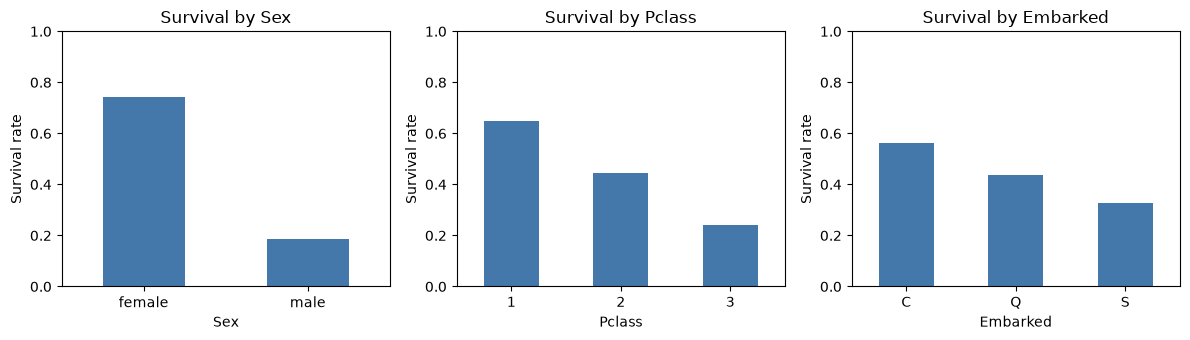

,count,mean
Sex,,
female,253,0.743083
male,459,0.185185


,count,mean
Pclass,,
1,171,0.649123
2,150,0.446667
3,391,0.242967


In [5]:
missing = pd.DataFrame({
    "Development missing": X_dev.isna().sum(),
    "Kaggle test missing": test.isna().sum(),
})
display(missing.loc[missing.any(axis=1)])
eda = X_dev.assign(Survived=y_dev)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for axis, feature in zip(axes, ["Sex", "Pclass", "Embarked"]):
    eda.groupby(feature)["Survived"].mean().plot.bar(ax=axis, color="#4477AA")
    axis.set(title=f"Survival by {feature}", ylabel="Survival rate", ylim=(0, 1))
    axis.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
display(eda.groupby("Sex")["Survived"].agg(["count", "mean"]))
display(eda.groupby("Pclass")["Survived"].agg(["count", "mean"]))

Sex and passenger class show clear differences in observed survival rates, motivating their use as predictors. Missing age and embarkation values require imputation. Cabin has substantial missingness, so the baseline excludes it. Section 11 tests an expanded feature set that includes cabin availability and deck.

## 4. Features and preprocessing
Our existing engineered features are:

| Feature | Definition | Motivation |
| --- | --- | --- |
| FamilySize | SibSp + Parch + 1 | Capture the size of the passenger's family group. |
| IsAlone | 1 when FamilySize is 1 | Distinguish passengers traveling without listed relatives. |
| Title | Title extracted from Name; uncommon/missing titles become Other | Capture additional demographic information. |

Feature extraction is row-by-row and learns no statistics. The pipeline then imputes numeric columns with training medians and categorical columns with training modes, scales numeric columns, and one-hot encodes Sex, Embarked, and Title. Unknown categories are ignored at prediction time. Pclass remains numeric to retain the existing baseline's treatment. PassengerId, raw Name, Ticket, and Cabin are excluded from model inputs.

The definitions in section 1 implement these transformations and pipelines. Repository tests cover missing values, unseen categories, and training-only imputation. See the [scikit-learn leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

In [6]:
display(engineer_features(X_dev)[
    ["Name", "FamilySize", "IsAlone", "Title"]
].head())

,Name,FamilySize,IsAlone,Title
692,"Lam, Mr. Ali",1,1,Mr
481,"Frost, Mr. Anthony Wood ""Archie""",1,1,Mr
527,"Farthing, Mr. John",1,1,Mr
855,"Aks, Mrs. Sam (Leah Rosen)",2,0,Mrs
801,"Collyer, Mrs. Harvey (Charlotte Annie Tate)",3,0,Mrs


## 5. Baseline comparison
The dummy classifier always predicts the most frequent training class. Logistic regression is a linear classifier; random forest can model nonlinear relationships. We retain the previous forest configuration (200 trees, maximum depth 5) and logistic regression iteration limit (1000).

All models receive the same folds and features. Numeric scaling is unnecessary for the forest but harmless and keeps preprocessing consistent. We record cross-validation scores before inspecting holdout diagnostics.

In [7]:
baseline_models = {
    "Dummy": make_pipeline(DummyClassifier(strategy="most_frequent")),
    "Logistic regression": make_pipeline(LogisticRegression(max_iter=1000)),
    "Random forest": make_pipeline(RandomForestClassifier(
        n_estimators=200, max_depth=5, random_state=SEED, n_jobs=1
    )),
}
cv_rows = []
for name, model in baseline_models.items():
    scores = cross_val_score(model, X_dev, y_dev, cv=cv, scoring="accuracy", n_jobs=1)
    cv_rows.append({"Model": name, "CV mean accuracy": scores.mean(),
                    "CV standard deviation": scores.std(), "Fold accuracies": scores.tolist()})
baseline_cv = pd.DataFrame(cv_rows).set_index("Model")
display(baseline_cv.drop(columns="Fold accuracies").round(4))

,CV mean accuracy,CV standard deviation
Model,,
Dummy,0.6166,0.0027
Logistic regression,0.8216,0.0224
Random forest,0.8329,0.0231


In [8]:
holdout_scores = {}
for name, model in baseline_models.items():
    fitted = clone(model).fit(X_dev, y_dev)
    holdout_scores[name] = accuracy_score(y_holdout, fitted.predict(X_holdout))
baseline_results = baseline_cv.drop(columns="Fold accuracies").copy()
baseline_results["Reused holdout accuracy"] = pd.Series(holdout_scores)
display(baseline_results.round(4))

,CV mean accuracy,CV standard deviation,Reused holdout accuracy
Model,,,
Dummy,0.6166,0.0027,0.6145
Logistic regression,0.8216,0.0224,0.8436
Random forest,0.8329,0.0231,0.8324


## 6. Historical Kaggle submissions
These scores are supported by the original screenshots. They are historical results, not scores for the regenerated pipelines above.

| Submission | Approach | Original local accuracy | Kaggle accuracy |
| --- | --- | --- | --- |
| Checkpoint 1 | Most-frequent dummy (all 0) | 0.616 training accuracy, not validation | 0.62200 |
| Checkpoint 2 | Logistic regression | 0.8547 on the earlier holdout workflow | 0.76794 |
| Checkpoint 2 | Random forest | 0.8324 on the earlier holdout workflow | 0.77751 |

The original local scores used preprocessing before the split and should not be treated as clean validation estimates. The Kaggle scores themselves remain valid records of the submitted predictions. Six non-dummy submissions are documented, including gradient boosting in section 8, the cleaned forest in section 9, regularized logistic regression in section 10, and compact-feature forest in section 11. The required six-upload minimum is met.

### Checkpoint 1 evidence
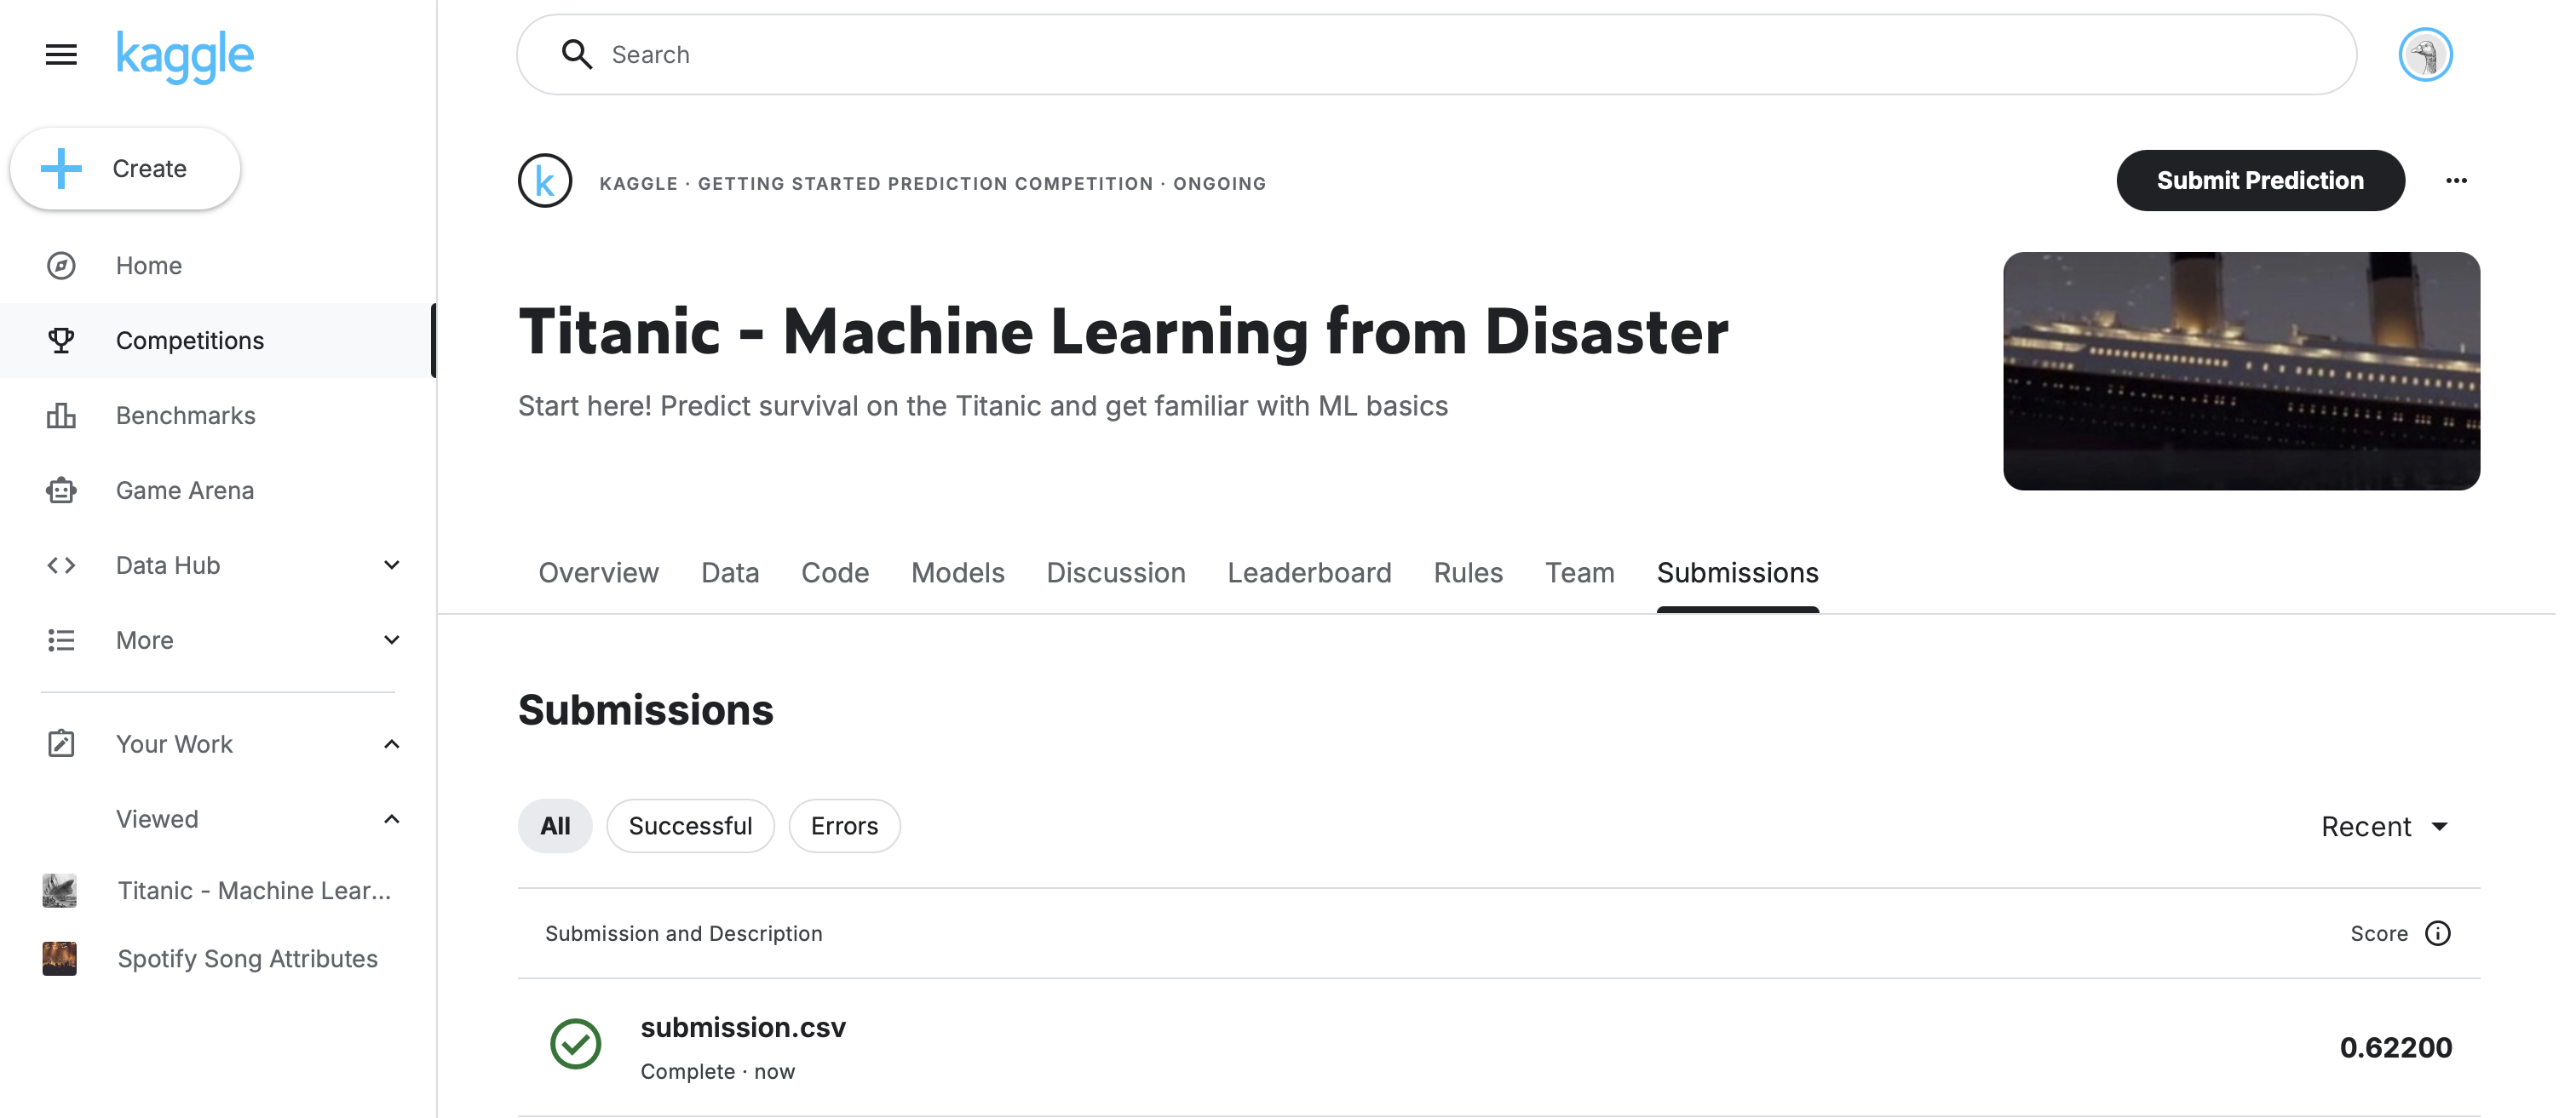

### Checkpoint 2 evidence
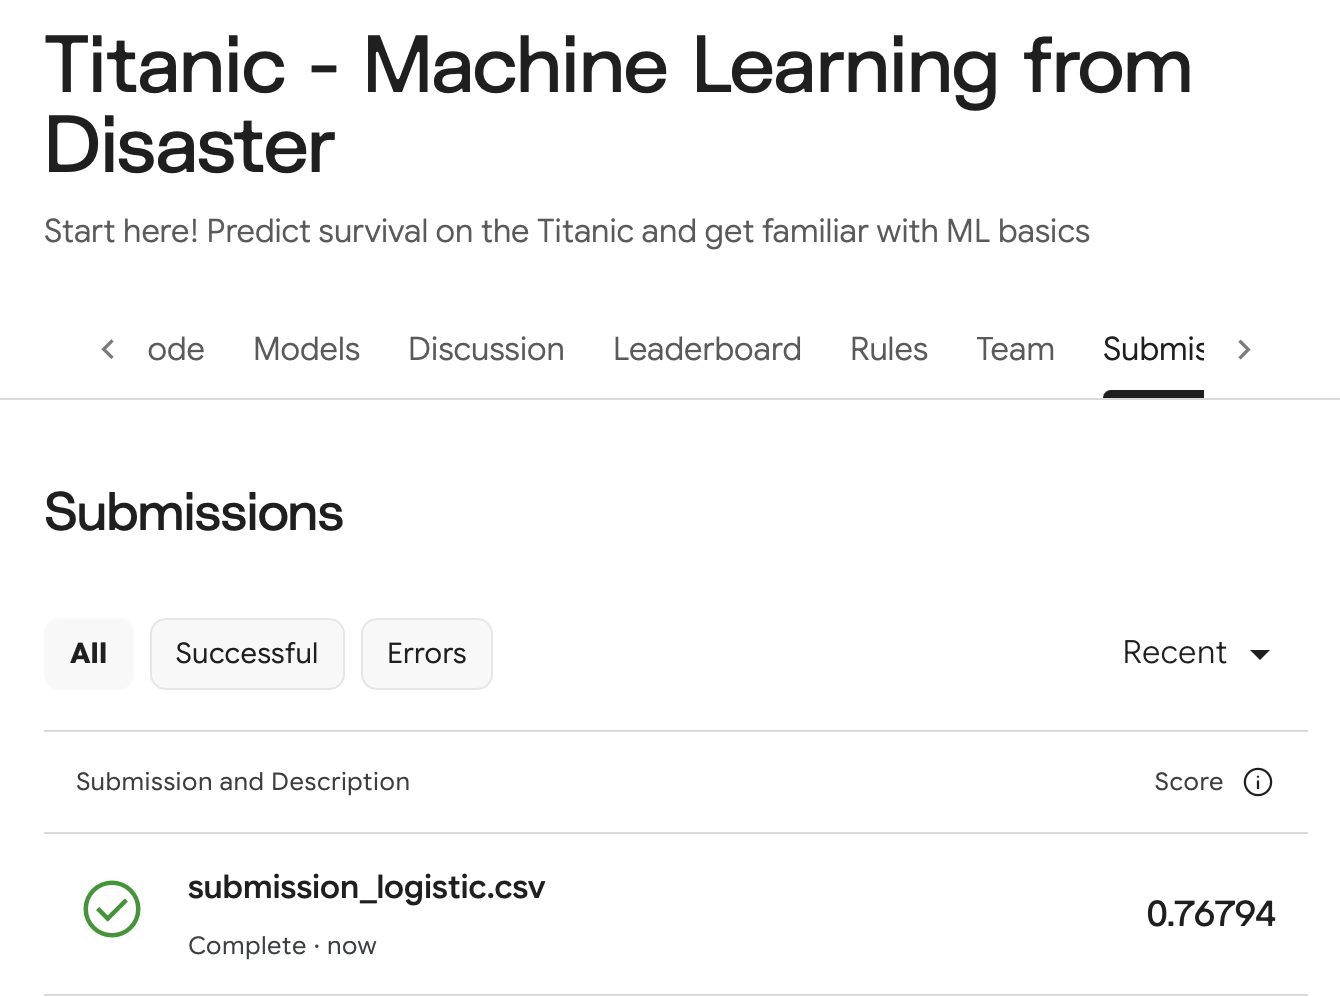

<details><summary>Original checkpoint 2 evidence, including the historical forest score of 0.77751</summary>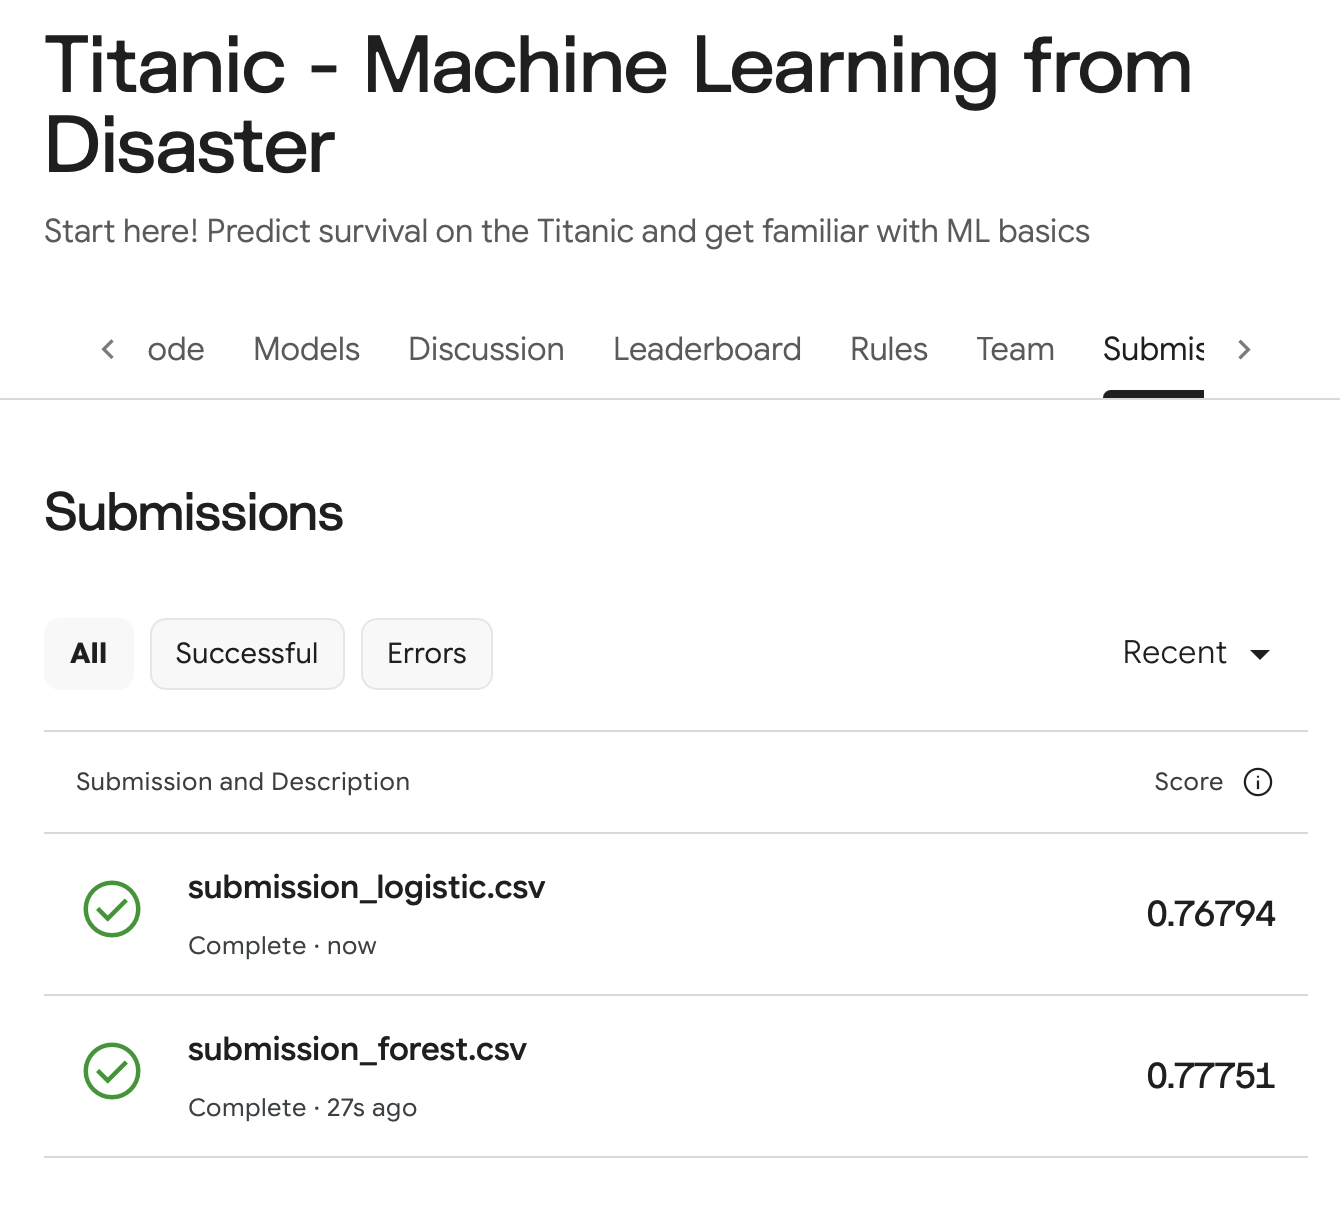</details>

## 7. Reproduce submission files
After evaluation, fit each pipeline on all 891 labeled passengers and predict the 418 Kaggle rows. The checked export preserves PassengerId order and rejects missing or non-binary predictions.

The dummy file is `submission.csv`. Refreshed model outputs have `_clean` suffixes to distinguish them from the historical uploads. Generated CSVs are ignored by Git and recreated by running this notebook.

In [9]:
submission_paths = {
    "Dummy": "submission.csv",
    "Logistic regression": "submission_logistic_clean.csv",
    "Random forest": "submission_forest_clean.csv",
}
for name, model in baseline_models.items():
    fitted = clone(model).fit(X, y)
    submission = make_submission(test["PassengerId"], fitted.predict(test))
    submission.to_csv(submission_paths[name], index=False)
    print(f"{submission_paths[name]}: {len(submission)} valid rows")

submission.csv: 418 valid rows
submission_logistic_clean.csv: 418 valid rows


submission_forest_clean.csv: 418 valid rows


## 8. Submission 3 experiment: gradient boosting
**Hypothesis:** shallow trees trained sequentially to correct earlier errors may capture interactions that the linear model misses and improve on the existing forest.

We hold the features, preprocessing, random seed, and development folds fixed. We compare only four configurations: maximum tree depth 2 or 3, and minimum leaf size 5 or 10. All use 200 boosting stages and learning rate 0.05. These settings are defined before running the search; we do not expand the search based on holdout or Kaggle scores.

Select the highest mean development CV accuracy within this gradient boosting experiment. Compare it with the existing baselines, then inspect its holdout accuracy once. Because this is the best of four configurations, its CV estimate has selection bias; a small lead is not proof of superiority. The completed upload and its score are recorded below.

In [10]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

boosting_search = GridSearchCV(
    make_pipeline(GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.05, random_state=SEED
    )),
    param_grid={"model__max_depth": [2, 3], "model__min_samples_leaf": [5, 10]},
    scoring="accuracy", cv=cv, n_jobs=1, refit=True, error_score="raise",
)
boosting_search.fit(X_dev, y_dev)
search_results = pd.DataFrame(boosting_search.cv_results_)
display(search_results[[
    "param_model__max_depth", "param_model__min_samples_leaf",
    "mean_test_score", "std_test_score", "rank_test_score",
]].sort_values("rank_test_score").round(4))
print("Selected parameters:", boosting_search.best_params_)
print(f"Selected development CV accuracy: {boosting_search.best_score_:.4f}")

,param_model__max_depth,param_model__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
3,3,10,0.8287,0.0210,1
2,3,5,0.8216,0.0267,2
1,2,10,0.8118,0.0194,3
0,2,5,0.8062,0.0113,4


Selected parameters: {'model__max_depth': 3, 'model__min_samples_leaf': 10}
Selected development CV accuracy: 0.8287


In [11]:
selected_boosting = boosting_search.best_estimator_
boosting_holdout_accuracy = accuracy_score(y_holdout, selected_boosting.predict(X_holdout))
comparison = baseline_results.copy()
comparison.loc["Gradient boosting (selected)"] = [
    boosting_search.best_score_,
    search_results.loc[boosting_search.best_index_, "std_test_score"],
    boosting_holdout_accuracy,
]
display(comparison.round(4))
cv_difference = boosting_search.best_score_ - baseline_cv.loc["Random forest", "CV mean accuracy"]
print(f"CV difference from random forest: {100 * cv_difference:+.2f} percentage points")
print("This is a development comparison, not a Kaggle score or proof of an improvement.")

,CV mean accuracy,CV standard deviation,Reused holdout accuracy
Model,,,
Dummy,0.6166,0.0027,0.6145
Logistic regression,0.8216,0.0224,0.8436
Random forest,0.8329,0.0231,0.8324
Gradient boosting (selected),0.8287,0.0210,0.8156


CV difference from random forest: -0.42 percentage points
This is a development comparison, not a Kaggle score or proof of an improvement.


### What this experiment tells us
The selected gradient boosting configuration uses depth 3 and minimum leaf size 10. It reached **0.8287 mean CV accuracy** (standard deviation 0.0210), compared with **0.8329** for the forest and **0.8216** for logistic regression. Its reused holdout accuracy was **0.8156**, below both existing non-dummy baselines.

This experiment does **not** support replacing random forest as our current CV leader. The CV gap is small relative to fold variation, and we have not established a statistically reliable difference. We retain gradient boosting as a distinct, documented method for submission 3, not as a claimed improvement. Its successful Kaggle upload on November 14, 2026 scored **0.76315**, below the historical forest score of **0.77751** by 1.436 percentage points. The historical forest used the earlier preprocessing, so that comparison does not isolate the algorithm alone.


### Fit, validate, and export the candidate
We now fit the selected configuration on all labeled data. This final fit may use every labeled row because model selection is finished for this experiment. We export predictions in the original test passenger order, reload the CSV, and check its schema, row count, IDs, and binary values.

The experiment metadata includes fold scores, selected parameters, package versions, a hash of the parsed training data, and the CSV SHA-256. This connects the evaluated configuration to the file intended for upload.

In [12]:
import hashlib
import json

final_boosting = clone(selected_boosting).fit(X, y)
submission_03 = make_submission(test["PassengerId"], final_boosting.predict(test))
submission_03_path = Path("submission_03_gradient_boosting.csv")
submission_03.to_csv(submission_03_path, index=False)
reloaded = pd.read_csv(submission_03_path)
assert reloaded.columns.tolist() == ["PassengerId", "Survived"]
assert len(reloaded) == len(test) == 418
assert reloaded["PassengerId"].equals(test["PassengerId"])
assert reloaded["Survived"].isin([0, 1]).all() and not reloaded.isna().any().any()
assert reloaded.equals(submission_03)

csv_hash = hashlib.sha256(submission_03_path.read_bytes()).hexdigest()
# Keep the observed score tied to the exact file prepared for this upload.
recorded_submission_sha256 = "f62ec98b8cd635808901b8021f71c8cf933182d4bfebb9c7b123ff2932e061a8"
matches_recorded_submission = csv_hash == recorded_submission_sha256
experiment = {
    "experiment": "03_gradient_boosting", "status": "matches_recorded_submission" if matches_recorded_submission else "prepared_not_uploaded",
    "seed": SEED, "development_rows": len(X_dev), "holdout_rows": len(X_holdout),
    "cv_folds": cv.n_splits, "cv_mean_accuracy": boosting_search.best_score_,
    "cv_std_accuracy": float(search_results.loc[boosting_search.best_index_, "std_test_score"]),
    "cv_fold_accuracies": [float(search_results.loc[boosting_search.best_index_, f"split{i}_test_score"])
                           for i in range(cv.n_splits)],
    "holdout_accuracy": boosting_holdout_accuracy, "holdout_previously_examined": True,
    "parameters": final_boosting.named_steps["model"].get_params(),
    "search_grid": boosting_search.param_grid,
    "baseline_cv_mean_accuracy": baseline_cv["CV mean accuracy"].to_dict(),
    "python": platform.python_version(), "sklearn": sklearn.__version__,
    "pandas": pd.__version__, "numpy": np.__version__,
    "training_data_sha256": hashlib.sha256(train.to_csv(index=False).encode()).hexdigest(),
    "submission_file": submission_03_path.name, "submission_sha256": csv_hash,
    "submission_rows": len(reloaded), "predicted_survivors": int(reloaded["Survived"].sum()),
    "kaggle_score": 0.76315 if matches_recorded_submission else None,
    "recorded_submission": {
        "date": "2026-11-14", "score": 0.76315,
        "submission_sha256": recorded_submission_sha256,
        "evidence": "assets/submission_03_score.png",
    },
}
Path("outputs").mkdir(exist_ok=True)
Path("outputs/experiment_03.json").write_text(json.dumps(experiment, indent=2) + "\n")
print(f"Generated file: {submission_03_path} ({len(reloaded)} checked rows)")
print(f"Predicted survivors: {reloaded['Survived'].sum()}")
print(f"SHA-256: {csv_hash}")
if matches_recorded_submission:
    print("Matches the November 14 submission: recorded Kaggle score 0.76315.")
else:
    print("Predictions differ from the recorded upload; this file has no Kaggle score yet.")
display(reloaded.head())

Generated file: submission_03_gradient_boosting.csv (418 checked rows)
Predicted survivors: 151
SHA-256: f62ec98b8cd635808901b8021f71c8cf933182d4bfebb9c7b123ff2932e061a8
Matches the November 14 submission: recorded Kaggle score 0.76315.


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


### Completed Kaggle submission
We submitted `submission_03_gradient_boosting.csv` on **November 14, 2026**. Kaggle reported **0.76315**. This was our third documented non-dummy submission; section 9 records the fourth.

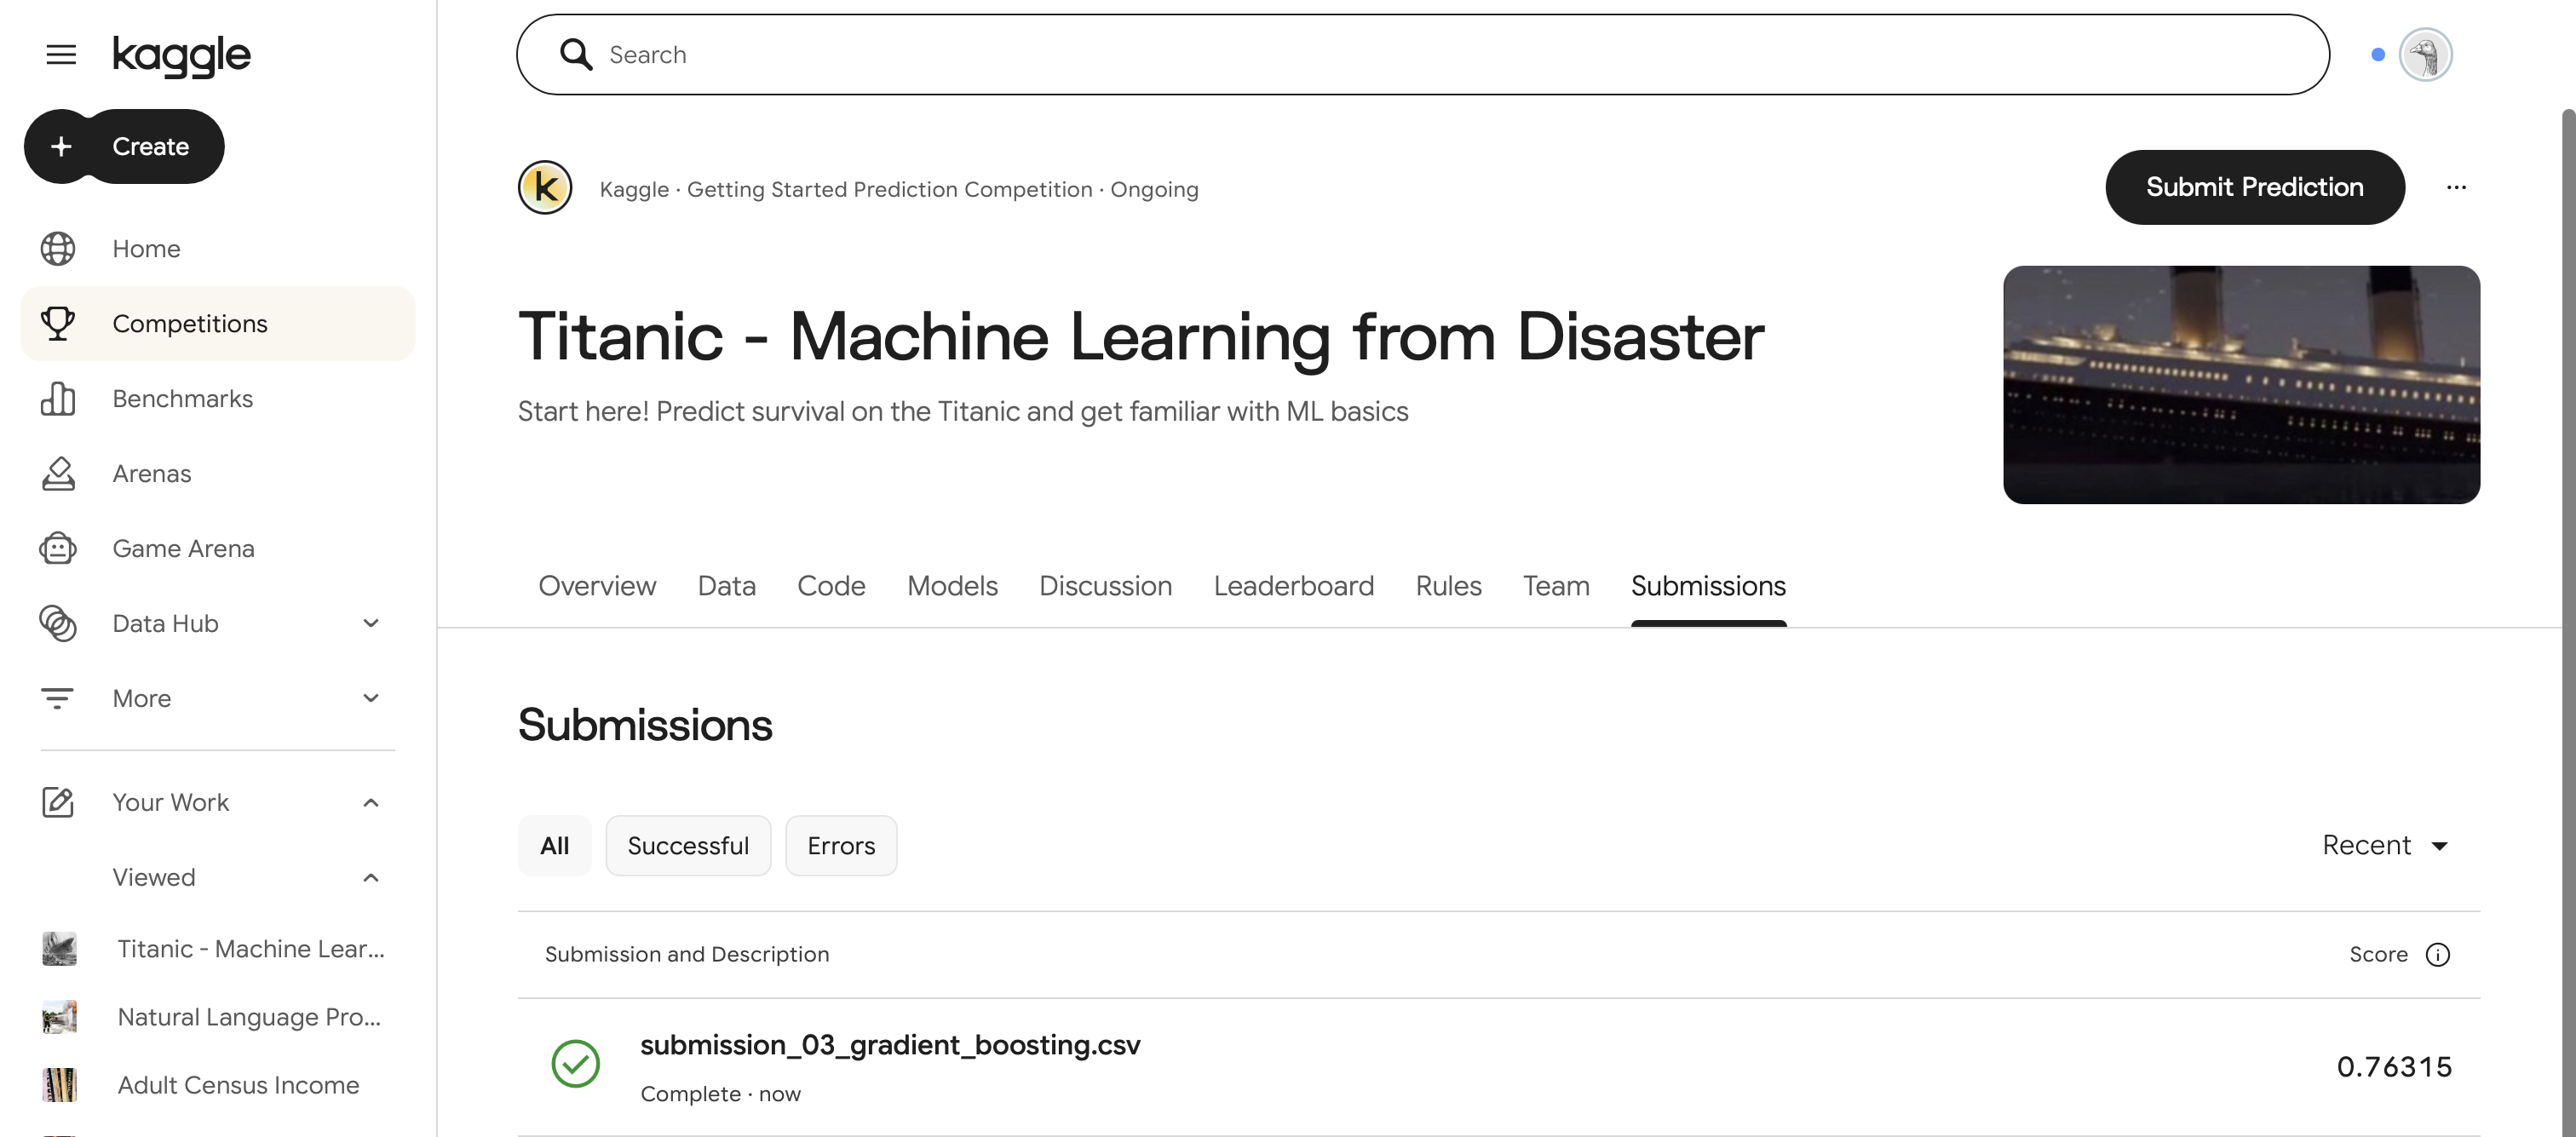

The score belongs to the uploaded file identified by the recorded hash in the export cell. The export cell compares the regenerated file hash with that record so a changed prediction file is not silently assigned the old score.

Section 9 evaluates submission 4: a small random forest parameter search with the same features and development CV folds.


## 9. Submission 4 experiment: tune the random forest
**Question:** Can changing tree depth and minimum leaf size improve the forest while keeping the features, preprocessing, and validation protocol fixed?

The forest leads our existing development CV comparison (0.8329). Its historical Kaggle score is also our highest recorded score (0.77751), although that upload used the older preprocessing. The control for this experiment is the **cleaned pipeline**, not the historical upload.

### What the settings mean
- `max_depth`: how many levels a tree can grow. We try 5, 8, and no explicit depth limit. More depth permits more detailed rules, with a risk of fitting noise.
- `min_samples_leaf`: the minimum number of training examples allowed in a leaf. We try 5, 3, and 1. Larger leaves discourage rules based on very few examples.

These nine settings are fixed before running the experiment. We keep 200 trees, seed 42, all other forest parameters, features, and five development folds unchanged. The grid includes the existing depth-5/leaf-1 control.

We select the highest mean CV accuracy. Exact ties use the first configuration in the grid: shallower trees, then larger minimum leaf size. Training accuracy is displayed to illustrate fitting behavior, not used to choose the winner. After selection, we inspect the reused holdout once and do not expand the search based on that result.

See the [random forest parameter documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).

In [13]:
forest_search = GridSearchCV(
    clone(baseline_models["Random forest"]),
    param_grid={"model__max_depth": [5, 8, None], "model__min_samples_leaf": [5, 3, 1]},
    scoring="accuracy", cv=cv, n_jobs=1, refit=True,
    return_train_score=True, error_score="raise",
)
forest_search.fit(X_dev, y_dev)
forest_search_results = pd.DataFrame(forest_search.cv_results_)
assert len(forest_search_results) == 9
control_mask = (
    (forest_search_results["param_model__max_depth"] == 5)
    & (forest_search_results["param_model__min_samples_leaf"] == 1)
)
assert control_mask.sum() == 1
control_index = forest_search_results.index[control_mask][0]
control_folds = np.array([
    forest_search_results.loc[control_index, f"split{i}_test_score"] for i in range(cv.n_splits)
])
np.testing.assert_allclose(
    control_folds, baseline_cv.loc["Random forest", "Fold accuracies"], rtol=0, atol=1e-12
)
forest_search_table = forest_search_results[[
    "param_model__max_depth", "param_model__min_samples_leaf",
    "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score",
]].copy()
forest_search_table.columns = [
    "Maximum depth", "Minimum leaf size", "Mean training accuracy",
    "Mean CV accuracy", "CV standard deviation", "CV rank",
]
# Display unlimited depth explicitly rather than as a missing value.
forest_search_table["Maximum depth"] = forest_search_table["Maximum depth"].map(
    lambda value: "Unlimited" if pd.isna(value) else str(int(value))
)
display(forest_search_table.sort_values("CV rank", kind="stable").round(4))
print("Control reproduced the original five fold scores exactly.")
print("Selected parameters:", forest_search.best_params_)
print(f"Selected mean CV accuracy: {forest_search.best_score_:.4f}")

,Maximum depth,Minimum leaf size,Mean training accuracy,Mean CV accuracy,CV standard deviation,CV rank
2,5,1,0.8473,0.8329,0.0231,1
1,5,3,0.8469,0.8287,0.0241,2
0,5,5,0.8416,0.8259,0.0252,3
7,Unlimited,3,0.8901,0.8217,0.0226,4
3,8,5,0.8648,0.8216,0.0185,5
6,Unlimited,5,0.8634,0.8202,0.0158,6
4,8,3,0.8806,0.8189,0.0230,7
5,8,1,0.9273,0.8160,0.0202,8
8,Unlimited,1,0.9838,0.7978,0.0101,9


Control reproduced the original five fold scores exactly.
Selected parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 1}
Selected mean CV accuracy: 0.8329


In [14]:
selected_forest = forest_search.best_estimator_
selected_forest_folds = np.array([
    forest_search_results.loc[forest_search.best_index_, f"split{i}_test_score"]
    for i in range(cv.n_splits)
])
forest_holdout_accuracy = accuracy_score(y_holdout, selected_forest.predict(X_holdout))
comparison_04 = comparison.copy()
comparison_04.loc["Random forest (tuned)"] = [
    forest_search.best_score_,
    forest_search_results.loc[forest_search.best_index_, "std_test_score"],
    forest_holdout_accuracy,
]
display(comparison_04.round(4))
fold_comparison_04 = pd.DataFrame({
    "Fold": range(1, cv.n_splits + 1), "Control accuracy": control_folds,
    "Tuned accuracy": selected_forest_folds,
    "Difference (percentage points)": 100 * (selected_forest_folds - control_folds),
})
display(fold_comparison_04.round(4))
forest_cv_difference = forest_search.best_score_ - baseline_cv.loc["Random forest", "CV mean accuracy"]
print(f"CV difference from the cleaned forest: {100 * forest_cv_difference:+.2f} percentage points")
print("The holdout was already examined in earlier work; this is a reused diagnostic.")
print("Selecting the best of nine configurations adds selection bias; a small CV gain is not proof of superiority.")

,CV mean accuracy,CV standard deviation,Reused holdout accuracy
Model,,,
Dummy,0.6166,0.0027,0.6145
Logistic regression,0.8216,0.0224,0.8436
Random forest,0.8329,0.0231,0.8324
Gradient boosting (selected),0.8287,0.0210,0.8156
Random forest (tuned),0.8329,0.0231,0.8324


,Fold,Control accuracy,Tuned accuracy,Difference (percentage points)
0,1,0.8392,0.8392,0.0
1,2,0.8112,0.8112,0.0
2,3,0.8732,0.8732,0.0
3,4,0.8099,0.8099,0.0
4,5,0.8310,0.8310,0.0


CV difference from the cleaned forest: +0.00 percentage points
The holdout was already examined in earlier work; this is a reused diagnostic.
Selecting the best of nine configurations adds selection bias; a small CV gain is not proof of superiority.


### What submission 4 teaches us
This controlled tuning experiment demonstrates searching two hyperparameters, comparing training and validation performance, and accepting a negative result. The upload records the cleaned pipeline's Kaggle score; it does not introduce a new model family.

The search retained **depth 5 and minimum leaf size 1**: our existing cleaned control. It achieved **0.8329 mean CV accuracy**, standard deviation **0.0231**, and **0.8324 reused holdout accuracy**. Every selected fold score equals the control's score.

The unlimited-depth/leaf-1 model reached **0.9838 training accuracy** but only **0.7978 CV accuracy**. This pattern is consistent with overfitting: more detailed trees memorized training examples without helping validation performance.

**Tuning did not improve our control.** The selected CSV contains exactly the same predictions as `submission_forest_clean.csv`; we did not force a worse setting to create different predictions. It is the cleaned pipeline prepared after checkpoint 2. The historical forest upload used different preprocessing, and its original CSV is not preserved here, so we cannot compare individual predictions directly. This file now has its own observed Kaggle score: **0.77511**, below the historical forest by **0.240 percentage points** and above gradient boosting by **1.196 percentage points**.

The exported filename refers to the tuning experiment, not a claim that the winning settings changed. Submission 4 was successfully uploaded and scored on November 14, 2026. A small search can still overfit the development folds, and the reused holdout is not a fresh final test.


### Generate submission 4
Model selection is finished for this experiment. Refit the chosen pipeline on all 891 labeled rows and generate predictions for the 418 test passengers. Check the CSV after writing it, and retain the configuration, all search results, fold scores, and file hash in `outputs/experiment_04.json`.

The generated file is **not uploaded automatically**. The observed score is attached only when its hash matches the file recorded for the successful November 14 upload. Changed predictions need their own upload and score.

In [15]:
final_tuned_forest = clone(selected_forest).fit(X, y)
submission_04 = make_submission(test["PassengerId"], final_tuned_forest.predict(test))
submission_04_path = Path("submission_04_random_forest_tuned.csv")
submission_04.to_csv(submission_04_path, index=False)
reloaded_04 = pd.read_csv(submission_04_path)
assert reloaded_04.columns.tolist() == ["PassengerId", "Survived"]
assert len(reloaded_04) == len(test) == 418
assert reloaded_04["PassengerId"].equals(test["PassengerId"])
assert reloaded_04["Survived"].isin([0, 1]).all() and not reloaded_04.isna().any().any()
pd.testing.assert_frame_equal(reloaded_04, submission_04)

# Compare predictions with the cleaned control, not its historical Kaggle upload.
control_predictions_04 = pd.read_csv("submission_forest_clean.csv")
assert control_predictions_04["PassengerId"].equals(test["PassengerId"])
changed_predictions_04 = int((reloaded_04["Survived"] != control_predictions_04["Survived"]).sum())
search_records_04 = []
for index, row in forest_search_results.iterrows():
    search_records_04.append({
        "parameters": row["params"], "cv_mean_accuracy": float(row["mean_test_score"]),
        "cv_std_accuracy": float(row["std_test_score"]),
        "mean_training_accuracy": float(row["mean_train_score"]),
        "cv_fold_accuracies": [float(row[f"split{i}_test_score"]) for i in range(cv.n_splits)],
    })
# Keep the recorded score tied to the exact file prepared for the completed upload.
recorded_submission_04_sha256 = "ad88ea3e445e7be3246c10fc2010ae25450b2ff50b568c34d76aed6022652438"
submission_04_sha256 = hashlib.sha256(submission_04_path.read_bytes()).hexdigest()
matches_recorded_submission_04 = submission_04_sha256 == recorded_submission_04_sha256
experiment_04 = {
    "experiment": "04_random_forest_tuned", "status": "matches_recorded_submission" if matches_recorded_submission_04 else "prepared_not_uploaded",
    "seed": SEED, "development_rows": len(X_dev), "holdout_rows": len(X_holdout),
    "cv_folds": cv.n_splits, "cv_mean_accuracy": forest_search.best_score_,
    "cv_std_accuracy": float(forest_search_results.loc[forest_search.best_index_, "std_test_score"]),
    "cv_fold_accuracies": selected_forest_folds.tolist(),
    "control_cv_fold_accuracies": control_folds.tolist(),
    "control_cv_mean_accuracy": float(control_folds.mean()),
    "holdout_accuracy": forest_holdout_accuracy, "holdout_previously_examined": True,
    "parameters": final_tuned_forest.named_steps["model"].get_params(),
    "search_grid": forest_search.param_grid, "search_results": search_records_04,
    "python": platform.python_version(), "sklearn": sklearn.__version__,
    "pandas": pd.__version__, "numpy": np.__version__,
    "training_data_sha256": hashlib.sha256(train.to_csv(index=False).encode()).hexdigest(),
    "test_data_sha256": hashlib.sha256(test.to_csv(index=False).encode()).hexdigest(),
    "submission_file": submission_04_path.name,
    "submission_sha256": submission_04_sha256,
    "submission_rows": len(reloaded_04), "predicted_survivors": int(reloaded_04["Survived"].sum()),
    "predictions_changed_from_cleaned_control": changed_predictions_04, "kaggle_score": 0.77511 if matches_recorded_submission_04 else None,
    "recorded_submission": {
        "date": "2026-11-14", "score": 0.77511,
        "submission_sha256": recorded_submission_04_sha256,
        "evidence": "assets/submission_04_score.png",
    },
}
Path("outputs/experiment_04.json").write_text(json.dumps(experiment_04, indent=2) + "\n")
print(f"Generated file: {submission_04_path} ({len(reloaded_04)} checked rows)")
print(f"Predicted survivors: {reloaded_04['Survived'].sum()}")
print(f"Predictions changed from the cleaned forest: {changed_predictions_04}")
print(f"SHA-256: {experiment_04['submission_sha256']}")
if matches_recorded_submission_04:
    print("Matches the November 14 submission: recorded Kaggle score 0.77511.")
else:
    print("Predictions differ from the recorded upload; this file has no Kaggle score yet.")
display(reloaded_04.head())

Generated file: submission_04_random_forest_tuned.csv (418 checked rows)
Predicted survivors: 164
Predictions changed from the cleaned forest: 0
SHA-256: ad88ea3e445e7be3246c10fc2010ae25450b2ff50b568c34d76aed6022652438
Matches the November 14 submission: recorded Kaggle score 0.77511.


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


### Completed Kaggle submission
We submitted `submission_04_random_forest_tuned.csv` on **November 14, 2026**. Kaggle reported **0.77511**. This was our fourth documented non-dummy submission; section 10 records the fifth.

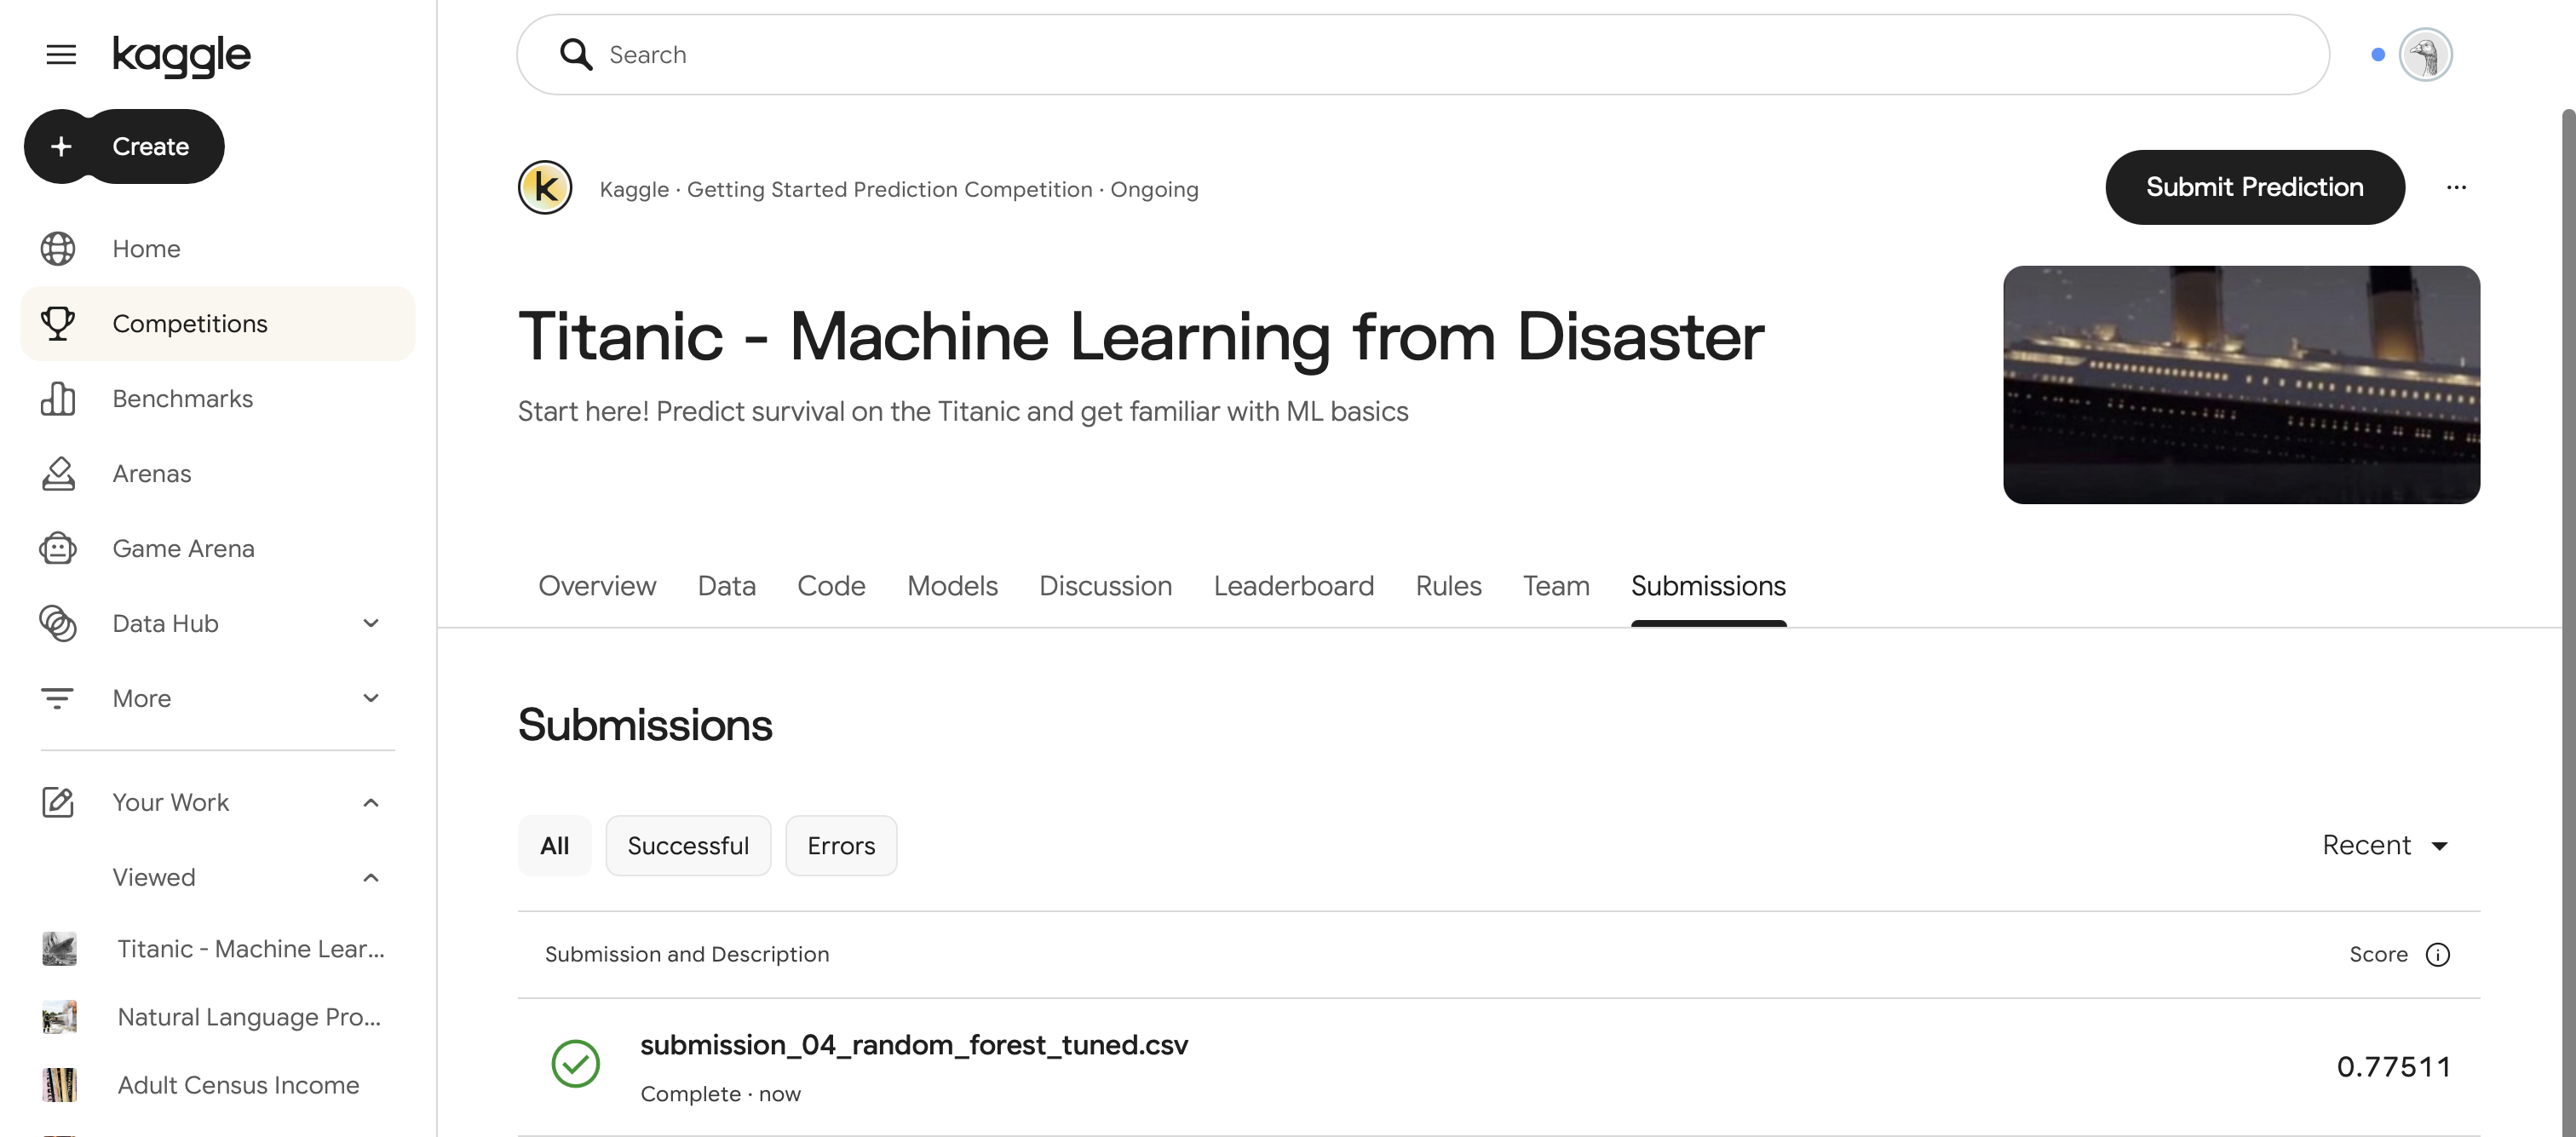

The score belongs to the file identified by the recorded hash in the export cell. The export cell checks the regenerated CSV hash before associating it with this score.

Section 10 adds classification metrics, error analysis, and logistic regression regularization for submission 5. Section 11 compares feature subsets and adds grouped permutation importance for submission 6.


## 10. Submission 5: logistic regression regularization and evaluation
**Question:** Can regularization or class weighting improve our linear baseline, and what do accuracy alone and additional classification metrics tell us?

This experiment follows the course template's linear-model tuning section and HW5's classification evaluation exercises. We keep the passenger features, preprocessing, 712 development rows, five stratified folds, and seed 42 unchanged.

### Fixed search and selection rule
- `C` = 0.01, 0.1, 1, 10, or 100. Smaller C means stronger regularization: larger coefficients are penalized more strongly. We use the existing L2 logistic regression with the lbfgs solver and max_iter=1000.
- `class_weight` = None or `balanced`. Balanced weighting gives more weight to the less common class using frequencies learned from each training fold. It changes training weights; it does not resample passengers or automatically improve accuracy.
- Select the highest mean development **accuracy**, the Kaggle metric. Exact ties favor the first grid entry: smaller C, then no class weighting.
- C=1 with no weighting is the existing cleaned logistic control. We verify that all five control accuracy scores reproduce the earlier baseline.
- No threshold tuning or additional grid search after looking at results. The reused holdout is diagnostic only; it has already been examined in previous experiments.

### Metrics and positive class
The positive class is **Survived=1**. Accuracy measures all correct labels. Precision asks how many predicted survivors actually survived; recall asks how many actual survivors were detected. F1 is their harmonic mean. ROC-AUC measures ranking across thresholds; average precision summarizes precision across recall changes and is not F1 or ROC-AUC. Accuracy chooses our submission; the others describe tradeoffs.

We use class predictions for accuracy/precision/recall/F1 and survival probabilities for ROC-AUC/average precision and curves. Undefined precision/F1 is recorded as zero (`zero_division=0`), which is relevant to the all-zero dummy model. Classification metrics are calculated only where ground-truth labels exist; the Kaggle test labels are unavailable.

References: [logistic regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html).

In [16]:
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
    average_precision_score, classification_report, confusion_matrix,
    f1_score, make_scorer, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import cross_validate

scoring_05 = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "recall": make_scorer(recall_score, pos_label=1, zero_division=0),
    "f1": make_scorer(f1_score, pos_label=1, zero_division=0),
    "roc_auc": make_scorer(roc_auc_score, response_method="predict_proba"),
    "average_precision": make_scorer(average_precision_score, response_method="predict_proba"),
}
logistic_search = GridSearchCV(
    clone(baseline_models["Logistic regression"]),
    param_grid={"model__C": [0.01, 0.1, 1, 10, 100], "model__class_weight": [None, "balanced"]},
    scoring=scoring_05, refit="accuracy", cv=cv, n_jobs=1,
    return_train_score=True, error_score="raise",
)
logistic_search.fit(X_dev, y_dev)
logistic_search_results = pd.DataFrame(logistic_search.cv_results_)
assert len(logistic_search_results) == 10
logistic_control_mask = (
    (logistic_search_results["param_model__C"] == 1)
    & logistic_search_results["param_model__class_weight"].isna()
)
assert logistic_control_mask.sum() == 1
logistic_control_index = logistic_search_results.index[logistic_control_mask][0]
logistic_control_folds = np.array([
    logistic_search_results.loc[logistic_control_index, f"split{i}_test_accuracy"]
    for i in range(cv.n_splits)
])
np.testing.assert_allclose(
    logistic_control_folds, baseline_cv.loc["Logistic regression", "Fold accuracies"],
    rtol=0, atol=1e-12,
)
logistic_search_table = logistic_search_results[[
    "param_model__C", "param_model__class_weight", "mean_train_accuracy",
    "mean_test_accuracy", "std_test_accuracy", "mean_test_precision",
    "mean_test_recall", "mean_test_f1",
]].copy()
logistic_search_table.columns = [
    "C", "Class weight", "Train accuracy", "CV accuracy", "CV accuracy std",
    "CV precision", "CV recall", "CV F1",
]
logistic_search_table["Class weight"] = logistic_search_table["Class weight"].fillna("None")
display(logistic_search_table.round(4))
print("Selected by accuracy:", logistic_search.best_params_)
print(f"Mean CV accuracy: {logistic_search.best_score_:.4f}")
print("Control reproduced the earlier five fold accuracy scores.")

,C,Class weight,Train accuracy,CV accuracy,CV accuracy std,CV precision,CV recall,CV F1
0,0.01,None,0.8013,0.7963,0.0267,0.8367,0.5859,0.6882
1,0.01,balanced,0.7992,0.7879,0.0262,0.7052,0.7765,0.7378
2,0.10,None,0.8202,0.8174,0.0232,0.7810,0.7326,0.7551
3,0.10,balanced,0.8100,0.8062,0.0237,0.7343,0.7841,0.7564
4,1.00,None,0.8283,0.8216,0.0224,0.7858,0.7400,0.7610
5,1.00,balanced,0.8153,0.8118,0.0264,0.7431,0.7877,0.7628
6,10.00,None,0.8279,0.8231,0.0199,0.7894,0.7400,0.7626
7,10.00,balanced,0.8132,0.8090,0.0225,0.7378,0.7877,0.7602
8,100.00,None,0.8290,0.8231,0.0199,0.7894,0.7400,0.7626
9,100.00,balanced,0.8129,0.8090,0.0233,0.7397,0.7840,0.7593


Selected by accuracy: {'model__C': 10, 'model__class_weight': None}
Mean CV accuracy: 0.8231
Control reproduced the earlier five fold accuracy scores.


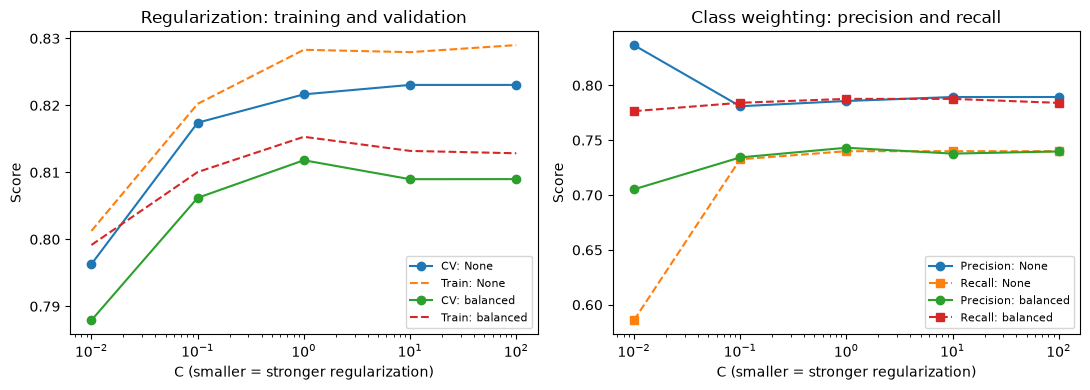

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for weight, group in logistic_search_table.groupby("Class weight"):
    axes[0].plot(group["C"], group["CV accuracy"], marker="o", label=f"CV: {weight}")
    axes[0].plot(group["C"], group["Train accuracy"], linestyle="--", label=f"Train: {weight}")
    axes[1].plot(group["C"], group["CV precision"], marker="o", label=f"Precision: {weight}")
    axes[1].plot(group["C"], group["CV recall"], marker="s", linestyle="--", label=f"Recall: {weight}")
for axis in axes:
    axis.set_xscale("log")
    axis.set_xlabel("C (smaller = stronger regularization)")
    axis.set_ylabel("Score")
    axis.legend(fontsize=8)
axes[0].set_title("Regularization: training and validation")
axes[1].set_title("Class weighting: precision and recall")
plt.tight_layout()
plt.show()

### Compare the existing models using multiple metrics
Every model receives the same development folds. The table reports mean CV scores; a second table includes accuracy variation, training accuracy, and timing. Fit and score times are per fold on this machine; score time includes computing all six metrics, not just making one prediction.

The selected logistic and gradient boosting configurations were chosen using these same development folds, so their estimates include selection bias. This table describes our development experiments; it is not a new independent evaluation.

In [18]:
metric_models_05 = {
    **baseline_models,
    "Gradient boosting (selected)": clone(selected_boosting),
    "Logistic regression (selected)": clone(logistic_search.best_estimator_),
}
cv_metric_records_05 = []
for name, model in metric_models_05.items():
    if name == "Logistic regression (selected)":
        row = logistic_search_results.loc[logistic_search.best_index_]
        scores = {f"test_{metric}": np.array([row[f"split{i}_test_{metric}"] for i in range(cv.n_splits)])
                  for metric in scoring_05}
        mean_train_accuracy = float(row["mean_train_accuracy"])
        fit_seconds, score_seconds = float(row["mean_fit_time"]), float(row["mean_score_time"])
    else:
        scores = cross_validate(
            model, X_dev, y_dev, cv=cv, scoring=scoring_05,
            return_train_score=True, n_jobs=1, error_score="raise",
        )
        mean_train_accuracy = float(scores["train_accuracy"].mean())
        fit_seconds, score_seconds = float(scores["fit_time"].mean()), float(scores["score_time"].mean())
        if name in baseline_cv.index:
            np.testing.assert_allclose(scores["test_accuracy"], baseline_cv.loc[name, "Fold accuracies"], rtol=0, atol=1e-12)
    record = {"Model": name}
    record.update({metric: float(scores[f"test_{metric}"].mean()) for metric in scoring_05})
    record.update({
        "Accuracy std": float(scores["test_accuracy"].std()), "Train accuracy": mean_train_accuracy,
        "Fit seconds": fit_seconds, "Score seconds": score_seconds,
    })
    cv_metric_records_05.append(record)
cv_metrics_05 = pd.DataFrame(cv_metric_records_05).set_index("Model")
display(cv_metrics_05[list(scoring_05)].round(4))
display(cv_metrics_05[["accuracy", "Accuracy std", "Train accuracy", "Fit seconds", "Score seconds"]].round(4))
assert cv_metrics_05.loc["Dummy", "recall"] == 0
print("The dummy model gets majority-class accuracy but detects no survivors (recall = 0).")

,accuracy,precision,recall,f1,roc_auc,average_precision
Model,,,,,,
Dummy,0.6166,0.0000,0.0000,0.0000,0.5000,0.3834
Logistic regression,0.8216,0.7858,0.7400,0.7610,0.8671,0.8540
Random forest,0.8329,0.8093,0.7398,0.7723,0.8717,0.8567
Gradient boosting (selected),0.8287,0.8049,0.7363,0.7676,0.8886,0.8635
Logistic regression (selected),0.8231,0.7894,0.7400,0.7626,0.8669,0.8558


,accuracy,Accuracy std,Train accuracy,Fit seconds,Score seconds
Model,,,,,
Dummy,0.6166,0.0027,0.6166,0.0064,0.0134
Logistic regression,0.8216,0.0224,0.8283,0.0084,0.0123
Random forest,0.8329,0.0231,0.8473,0.1392,0.0294
Gradient boosting (selected),0.8287,0.0210,0.9045,0.1200,0.0141
Logistic regression (selected),0.8231,0.0199,0.8279,0.0081,0.0112


The dummy model gets majority-class accuracy but detects no survivors (recall = 0).


### Reused holdout: which errors do the models make?
Fit each fixed configuration on the development rows only, then predict the same 179-row holdout. No model or threshold is chosen using these results. Rows of each confusion matrix are actual classes; columns are predicted classes.

A false negative is an actual survivor predicted not to survive. A false positive is a nonsurvivor predicted to survive. This is retrospective historical prediction, not a model for assigning rescue resources. The curves describe how error tradeoffs change across thresholds; our exported labels still use each classifier's standard prediction rule.

,accuracy,precision,recall,f1,roc_auc,average_precision
Model,,,,,,
Dummy,0.6145,0.0000,0.0000,0.0000,0.5000,0.3855
Logistic regression,0.8436,0.8254,0.7536,0.7879,0.8792,0.8434
Random forest,0.8324,0.8095,0.7391,0.7727,0.8601,0.8372
Gradient boosting (selected),0.8156,0.8103,0.6812,0.7402,0.8412,0.7992
Logistic regression (selected),0.8547,0.8413,0.7681,0.8030,0.8829,0.8494


,TN,FP,FN,TP
Model,,,,
Dummy,110,0,69,0
Logistic regression,99,11,17,52
Random forest,98,12,18,51
Gradient boosting (selected),99,11,22,47
Logistic regression (selected),100,10,16,53


Selected logistic classification report (reused holdout):
                 precision    recall  f1-score   support

Did not survive       0.86      0.91      0.88       110
       Survived       0.84      0.77      0.80        69

       accuracy                           0.85       179
      macro avg       0.85      0.84      0.84       179
   weighted avg       0.85      0.85      0.85       179



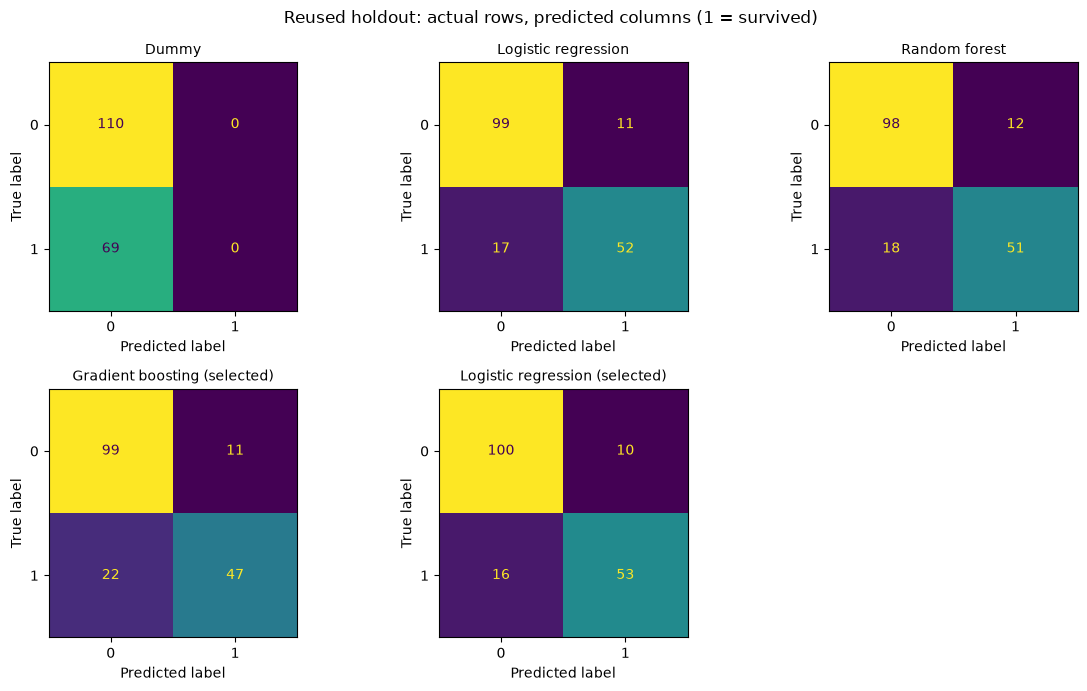

In [19]:
holdout_records_05 = []
holdout_predictions_05 = {}
holdout_probabilities_05 = {}
confusion_matrices_05 = {}
for name, model in metric_models_05.items():
    fitted = clone(model).fit(X_dev, y_dev)
    np.testing.assert_array_equal(fitted.classes_, [0, 1])
    prediction = fitted.predict(X_holdout)
    probability = fitted.predict_proba(X_holdout)[:, 1]
    assert np.isfinite(probability).all() and ((probability >= 0) & (probability <= 1)).all()
    holdout_predictions_05[name] = prediction
    holdout_probabilities_05[name] = probability
    matrix = confusion_matrix(y_holdout, prediction, labels=[0, 1])
    assert matrix.sum() == len(y_holdout)
    confusion_matrices_05[name] = matrix.tolist()
    tn, fp, fn, tp = matrix.ravel()
    holdout_records_05.append({
        "Model": name, "accuracy": accuracy_score(y_holdout, prediction),
        "precision": precision_score(y_holdout, prediction, zero_division=0),
        "recall": recall_score(y_holdout, prediction, zero_division=0),
        "f1": f1_score(y_holdout, prediction, zero_division=0),
        "roc_auc": roc_auc_score(y_holdout, probability),
        "average_precision": average_precision_score(y_holdout, probability),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    })
holdout_metrics_05 = pd.DataFrame(holdout_records_05).set_index("Model")
display(holdout_metrics_05[list(scoring_05)].round(4))
display(holdout_metrics_05[["TN", "FP", "FN", "TP"]])
print("Selected logistic classification report (reused holdout):")
print(classification_report(
    y_holdout, holdout_predictions_05["Logistic regression (selected)"],
    labels=[0, 1], target_names=["Did not survive", "Survived"], zero_division=0,
))
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for axis, (name, prediction) in zip(axes.flat, holdout_predictions_05.items()):
    ConfusionMatrixDisplay.from_predictions(y_holdout, prediction, labels=[0, 1], ax=axis, colorbar=False)
    axis.set_title(name, fontsize=10)
axes.flat[-1].set_visible(False)
fig.suptitle("Reused holdout: actual rows, predicted columns (1 = survived)")
plt.tight_layout()
plt.show()

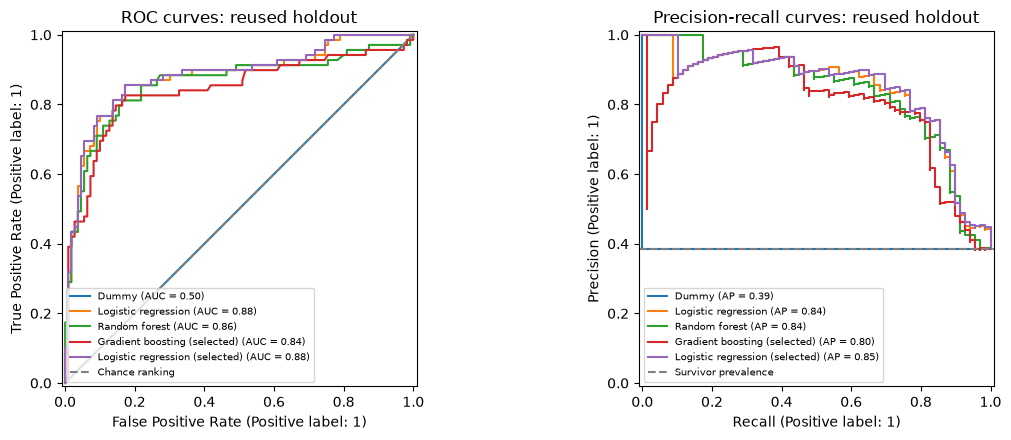

ROC-AUC and average precision evaluate rankings, not just the exported 0/1 decisions.
The holdout has been reused; these plots do not remove optimization bias.


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, probability in holdout_probabilities_05.items():
    RocCurveDisplay.from_predictions(y_holdout, probability, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_holdout, probability, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance ranking")
axes[1].axhline(y_holdout.mean(), linestyle="--", color="gray", label="Survivor prevalence")
axes[0].set_title("ROC curves: reused holdout")
axes[1].set_title("Precision-recall curves: reused holdout")
for axis in axes:
    axis.legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.show()
print("ROC-AUC and average precision evaluate rankings, not just the exported 0/1 decisions.")
print("The holdout has been reused; these plots do not remove optimization bias.")

### What we learned from submission 5
The accuracy rule selects **C=10 with no class weighting**. C=100 ties exactly, so the declared tie rule keeps the stronger regularization at C=10. Mean CV accuracy is **0.8231**, compared with **0.8216** for C=1: a gain of only **0.14 percentage points**. Fold standard deviation is 0.0199, and selection reused these folds. This small difference does not establish a generalization improvement. Random forest still leads development accuracy at 0.8329.

At C=10, balanced weighting raises mean survivor recall from **0.7400 to 0.7877**, while precision falls from **0.7894 to 0.7378** and accuracy from **0.8231 to 0.8090**. Weighting makes a different error tradeoff, so it is not automatically better. Very strong regularization (C=0.01, unweighted) yields high precision (0.8367) but low recall (0.5859), missing many survivors. Weakening regularization beyond C=10 does not improve validation accuracy in this grid.

The multimetric comparison explains why accuracy is incomplete: the dummy reaches 0.6166 accuracy while detecting no survivors. Gradient boosting has the highest development ROC-AUC (0.8886) and average precision (0.8635), while forest has the highest accuracy. Ranking quality and accuracy at the standard prediction rule answer different questions. The selected logistic fit takes about 0.009 seconds per fold versus 0.126 for forest in the initial submission 5 run; these are machine-specific measurements on a small dataset, not a general speed benchmark.

On the **reused** holdout, selected logistic regression gets 153 of 179 labels right (0.8547 accuracy): TN=100, FP=10, FN=16, TP=53. Survivor precision is 0.8413, recall 0.7681, and F1 0.8030. It misses 16 actual survivors and predicts survival for 10 nonsurvivors. This diagnostic does not override the development selection protocol or make the holdout fresh again.

The final CSV differs from the cleaned default logistic export in **only one of 418 labels**. This is a tuning and evaluation experiment within an existing model family; its main contribution is understanding regularization, class weighting, and errors. Its successful Kaggle upload scored **0.77033**, 0.478 percentage points below submission 4's forest (0.77511). It is 0.239 points above the historical logistic score (0.76794), but that earlier upload used different preprocessing, so this does not isolate regularization. We have no separately recorded Kaggle score for the cleaned C=1 control. Forest remains our leading approach.

### Refit and export submission 5
The selected logistic configuration is refitted on all 891 labeled rows only after selection and diagnostics. The export is validated after a CSV round trip. We record all ten configurations and metrics, the selected settings, data hashes, and the final prediction hash.

This is our regularized linear-model experiment, not an automatic replacement for the forest. The recorded Kaggle score is 0.77033. The export cell associates that score with a regenerated CSV only when its hash matches the file recorded for the completed upload; changed predictions require their own upload and score.

In [21]:
final_logistic_05 = clone(logistic_search.best_estimator_).fit(X, y)
submission_05 = make_submission(test["PassengerId"], final_logistic_05.predict(test))
submission_05_path = Path("submission_05_logistic_regularized.csv")
submission_05.to_csv(submission_05_path, index=False)
reloaded_05 = pd.read_csv(submission_05_path)
assert reloaded_05.columns.tolist() == ["PassengerId", "Survived"]
assert len(reloaded_05) == len(test) == 418
assert reloaded_05["PassengerId"].equals(test["PassengerId"])
assert reloaded_05["Survived"].isin([0, 1]).all() and not reloaded_05.isna().any().any()
pd.testing.assert_frame_equal(reloaded_05, submission_05)
logistic_control_predictions_05 = pd.read_csv("submission_logistic_clean.csv")
assert logistic_control_predictions_05["PassengerId"].equals(test["PassengerId"])
changed_logistic_predictions_05 = int((reloaded_05["Survived"] != logistic_control_predictions_05["Survived"]).sum())
search_records_05 = []
for _, row in logistic_search_results.iterrows():
    search_records_05.append({
        "parameters": row["params"], "mean_training_accuracy": float(row["mean_train_accuracy"]),
        "cv_mean": {metric: float(row[f"mean_test_{metric}"]) for metric in scoring_05},
        "cv_std": {metric: float(row[f"std_test_{metric}"]) for metric in scoring_05},
        "cv_fold_accuracy": [float(row[f"split{i}_test_accuracy"]) for i in range(cv.n_splits)],
        "mean_fit_seconds": float(row["mean_fit_time"]), "mean_score_seconds": float(row["mean_score_time"]),
    })
selected_record_05 = search_records_05[logistic_search.best_index_]
# Associate the historical score only with the exact uploaded prediction file.
recorded_submission_05_sha256 = "b218945305ce8b9e468e1ae3a1a35d7cbd5dd4022115e54bdd08779168095ff0"
submission_05_sha256 = hashlib.sha256(submission_05_path.read_bytes()).hexdigest()
matches_recorded_submission_05 = submission_05_sha256 == recorded_submission_05_sha256
experiment_05 = {
    "experiment": "05_logistic_regularized", "status": "matches_recorded_submission" if matches_recorded_submission_05 else "prepared_not_uploaded",
    "kaggle_score": 0.77033 if matches_recorded_submission_05 else None,
    "positive_class": 1, "selection_metric": "accuracy", "seed": SEED,
    "development_rows": len(X_dev), "holdout_rows": len(X_holdout), "cv_folds": cv.n_splits,
    "selected_search_index": int(logistic_search.best_index_),
    "cv_mean": selected_record_05["cv_mean"], "cv_std": selected_record_05["cv_std"],
    "cv_fold_accuracy": selected_record_05["cv_fold_accuracy"],
    "control_cv_fold_accuracy": logistic_control_folds.tolist(),
    "holdout_metrics": holdout_metrics_05.loc["Logistic regression (selected)"].to_dict(),
    "holdout_previously_examined": True,
    "parameters": final_logistic_05.named_steps["model"].get_params(),
    "search_grid": logistic_search.param_grid, "search_results": search_records_05,
    "cv_model_comparison": cv_metrics_05.to_dict(orient="index"),
    "holdout_model_comparison": holdout_metrics_05.to_dict(orient="index"),
    "holdout_confusion_matrices": confusion_matrices_05,
    "python": platform.python_version(), "sklearn": sklearn.__version__,
    "pandas": pd.__version__, "numpy": np.__version__,
    "training_data_sha256": hashlib.sha256(train.to_csv(index=False).encode()).hexdigest(),
    "test_data_sha256": hashlib.sha256(test.to_csv(index=False).encode()).hexdigest(),
    "submission_file": submission_05_path.name,
    "submission_sha256": submission_05_sha256,
    "submission_rows": len(reloaded_05), "predicted_survivors": int(reloaded_05["Survived"].sum()),
    "predictions_changed_from_cleaned_logistic": changed_logistic_predictions_05,
    "recorded_submission": {
        "date": "2026-11-14", "score": 0.77033,
        "submission_sha256": recorded_submission_05_sha256,
        "evidence": "assets/submission_05_score.png",
    },
}
Path("outputs/experiment_05.json").write_text(json.dumps(experiment_05, indent=2) + "\n")
print(f"Generated file: {submission_05_path} ({len(reloaded_05)} validated rows)")
print(f"Predicted survivors: {reloaded_05['Survived'].sum()}")
print(f"Predictions changed from cleaned logistic control: {changed_logistic_predictions_05}")
print(f"SHA-256: {experiment_05['submission_sha256']}")
if matches_recorded_submission_05:
    print("Matches the November 14 submission: recorded Kaggle score 0.77033.")
else:
    print("Predictions differ from the recorded upload; this file has no Kaggle score yet.")
display(reloaded_05.head())

Generated file: submission_05_logistic_regularized.csv (418 validated rows)
Predicted survivors: 164
Predictions changed from cleaned logistic control: 1
SHA-256: b218945305ce8b9e468e1ae3a1a35d7cbd5dd4022115e54bdd08779168095ff0
Matches the November 14 submission: recorded Kaggle score 0.77033.


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


### Completed Kaggle submission
We submitted `submission_05_logistic_regularized.csv` on **November 14, 2026**. Kaggle reported **0.77033**. This was the fifth documented non-dummy submission; section 11 records the sixth.

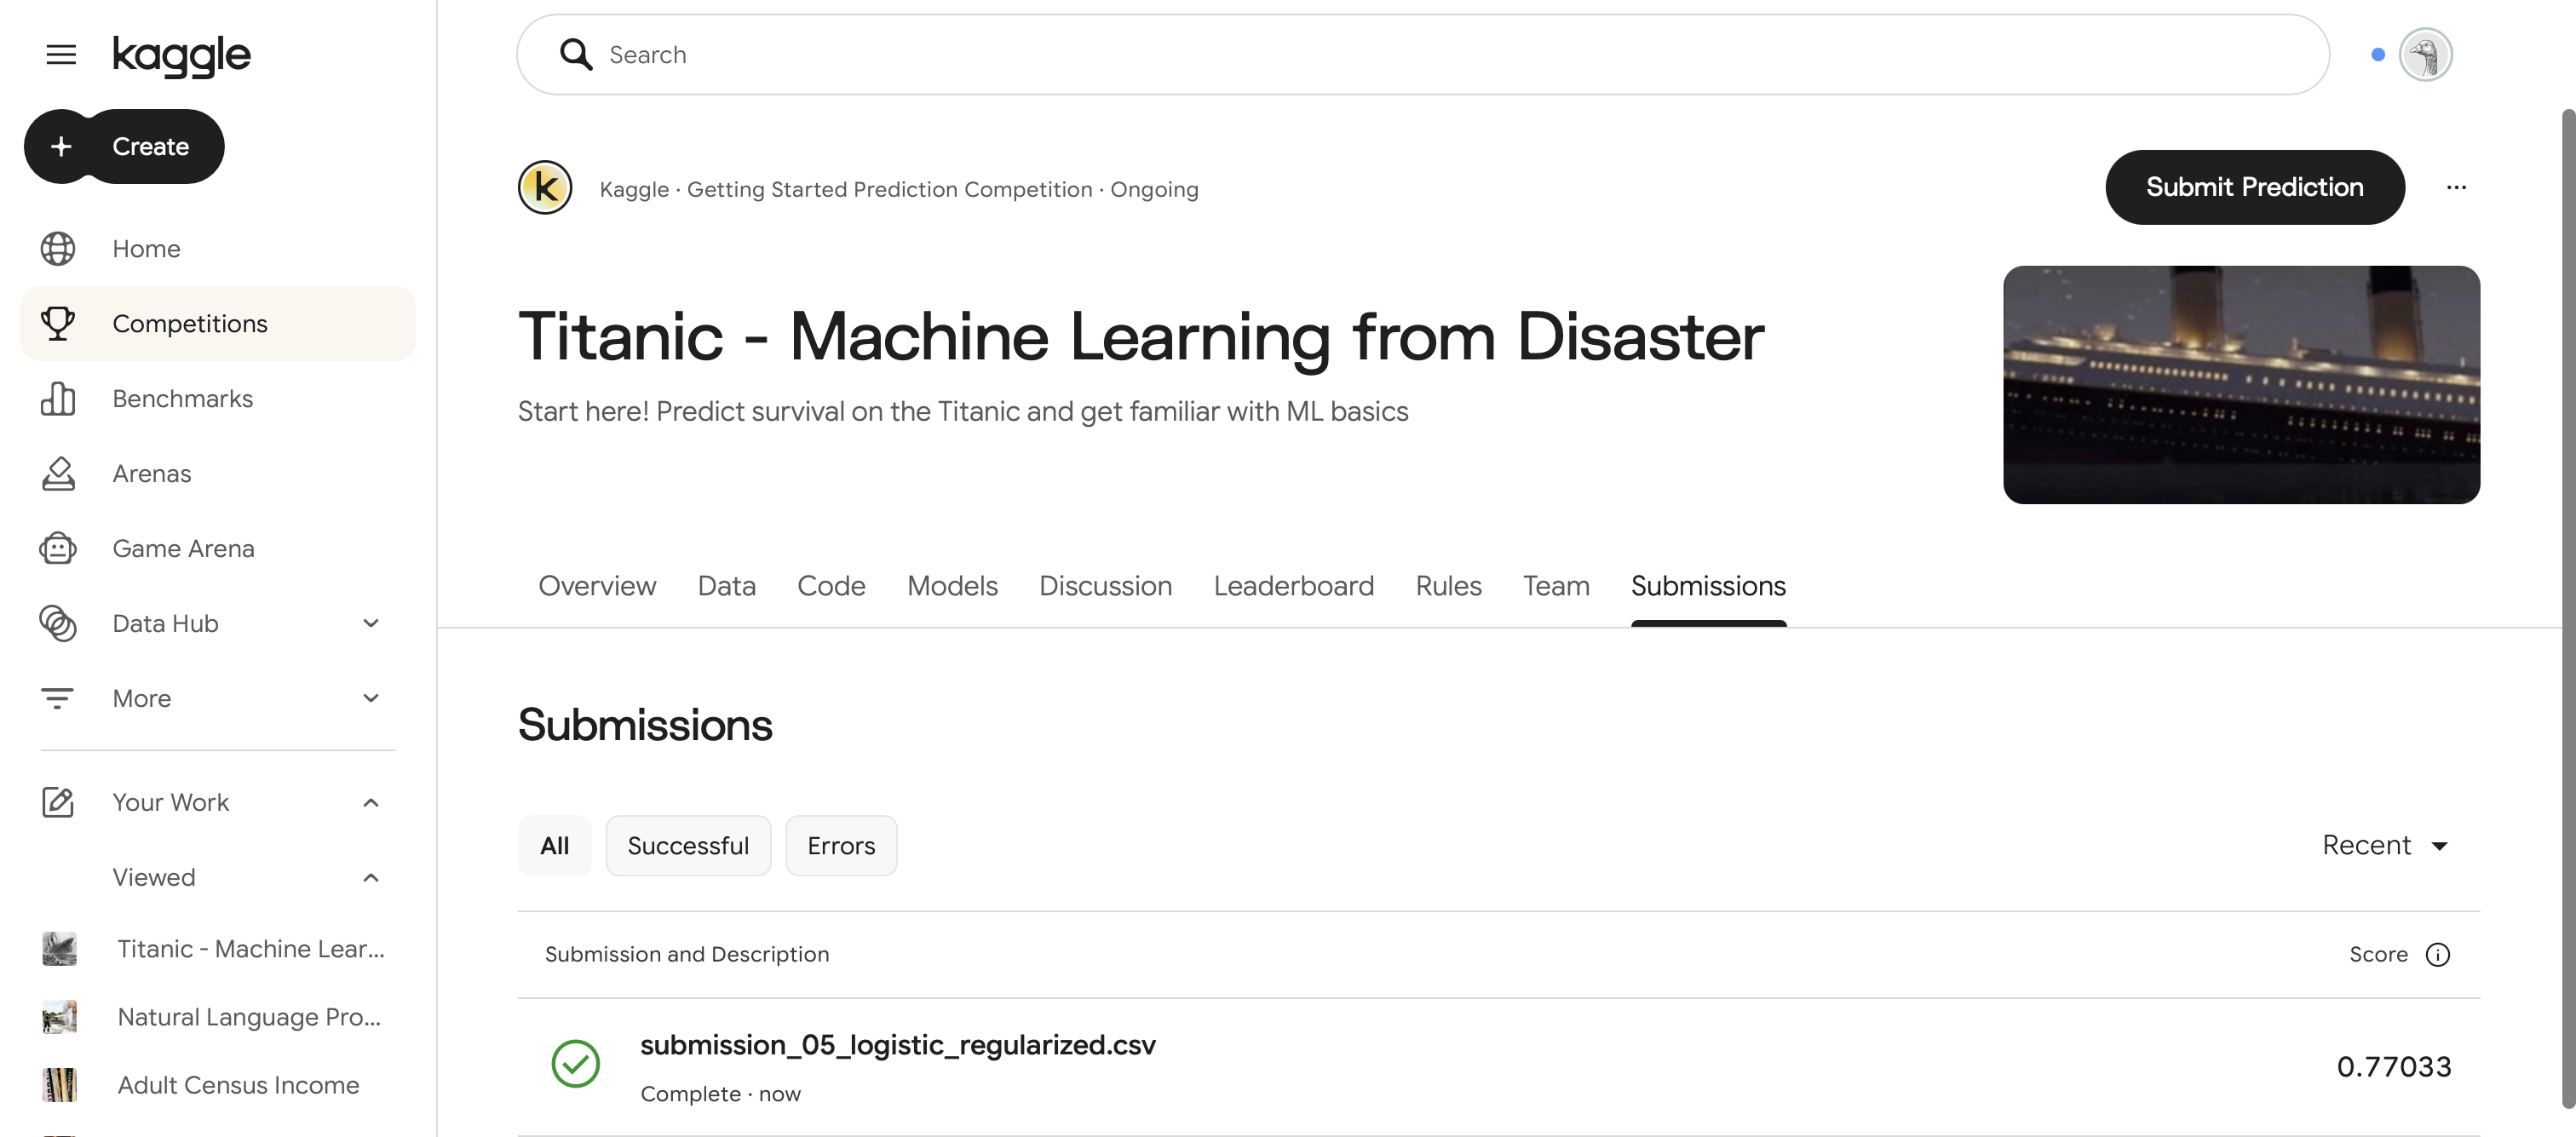

The score belongs to the file identified by the recorded hash in the export cell. The export cell checks the regenerated CSV hash before associating it with this score. Section 11 implements the feature comparison and interpretation experiment for submission 6.

## 11. Submission 6: feature selection, engineering, and interpretation
**Question:** Which predefined feature set works best with our existing forest, and which passenger information does the selected model rely on?

We hold the classifier fixed: 200 trees, depth 5, minimum leaf size 1, seed 42. The same 712 development rows and five stratified folds select the feature set. All imputation and encoding are fitted inside each training fold.

| Set | Numeric inputs | Categorical inputs | Question |
| --- | --- | --- | --- |
| basic | Pclass, Age, SibSp, Parch, Fare | Sex, Embarked | Do the engineered title/family fields help as a bundle? |
| compact | Pclass, Age, Fare, FamilySize, IsAlone | Sex, Embarked, Title | Can we remove the separate SibSp/Parch counts? |
| baseline | Pclass, Age, SibSp, Parch, Fare, FamilySize, IsAlone | Sex, Embarked, Title | Reproduce our cleaned forest control |
| extended | Baseline numeric inputs plus HasCabin, FarePerPerson | Baseline categorical inputs plus Deck | Does cabin information and normalized fare help as a bundle? |

HasCabin is 1 for a nonempty cabin string. Deck is its first letter, or Unknown. FarePerPerson divides Fare by FamilySize. This is only a proxy: a ticket's fare need not cover exactly the listed family. These features use one passenger row at a time and no survival labels. Missing fare stays missing until the training-fold median is fitted.

Select highest mean development **accuracy**. Exact ties favor fewer input columns, then the table order. We predeclared these four sets; we do not expand the search or retune the forest afterward. These bundle comparisons cannot isolate each added feature's effect. The forest still uses max_features="sqrt", so changing the encoded feature count also changes how many candidates a split considers.

This is manual feature-subset selection through validation, not an automatic selector trained on the full dataset. Searching subsets on these folds creates selection bias. The holdout remains reused and diagnostic; Kaggle scores do not choose the subset.

**Delivery decision after observing this fixed comparison:** the baseline won and its export would duplicate submission 4. For a distinct sixth experiment, we prepared the highest-accuracy non-baseline set as an **ablation candidate**, while retaining the baseline as the best model. This upload decision was made after seeing the four results; it is not the original overall-winner rule. No configurations were added or retuned, and no leaderboard or holdout score chose the alternative. A lower-scoring experiment is useful evidence, not an improvement claim.

In [22]:
forest_estimator_06 = RandomForestClassifier(
    n_estimators=200, max_depth=5, min_samples_leaf=1, random_state=SEED, n_jobs=1
)
feature_runs_06 = {}
feature_records_06 = []
fold_indices_06 = list(cv.split(X_dev, y_dev))
for name, (numeric, categorical) in FEATURE_SETS.items():
    candidate = make_pipeline(forest_estimator_06, feature_set=name)
    result = cross_validate(
        candidate, X_dev, y_dev, cv=fold_indices_06, scoring=scoring_05,
        return_train_score=True, return_estimator=True, n_jobs=1, error_score="raise",
    )
    feature_runs_06[name] = result
    feature_records_06.append({
        "Feature set": name, "Input columns": len(numeric) + len(categorical),
        "Train accuracy": float(result["train_accuracy"].mean()),
        **{metric: float(result[f"test_{metric}"].mean()) for metric in scoring_05},
        "Accuracy std": float(result["test_accuracy"].std()),
        "Fit seconds": float(result["fit_time"].mean()),
    })
feature_table_06 = pd.DataFrame(feature_records_06).set_index("Feature set")
np.testing.assert_allclose(
    feature_runs_06["baseline"]["test_accuracy"],
    baseline_cv.loc["Random forest", "Fold accuracies"], rtol=0, atol=1e-12,
)
selected_features_06 = max(
    FEATURE_SETS,
    key=lambda name: (feature_table_06.loc[name, "accuracy"], -feature_table_06.loc[name, "Input columns"]),
)
# Keep the overall winner separate from the distinct experiment prepared for upload.
submission_features_06 = max(
    (name for name in FEATURE_SETS if name != "baseline"),
    key=lambda name: (feature_table_06.loc[name, "accuracy"], -feature_table_06.loc[name, "Input columns"]),
)
submission_pipeline_06 = make_pipeline(forest_estimator_06, feature_set=submission_features_06)
display(feature_table_06[["Input columns", "Train accuracy", "accuracy", "Accuracy std"]].round(4))
display(feature_table_06[list(scoring_05)].round(4))
print("Overall CV winner:", selected_features_06)
print("Distinct ablation candidate for upload:", submission_features_06)
print("Control reproduced all five earlier forest fold scores.")

,Input columns,Train accuracy,accuracy,Accuracy std
Feature set,,,,
basic,7,0.8631,0.8174,0.0260
compact,8,0.8539,0.8244,0.0213
baseline,10,0.8473,0.8329,0.0231
extended,13,0.8704,0.8217,0.0289


,accuracy,precision,recall,f1,roc_auc,average_precision
Feature set,,,,,,
basic,0.8174,0.8274,0.6628,0.7351,0.8707,0.8511
compact,0.8244,0.8082,0.7141,0.7569,0.8702,0.8552
baseline,0.8329,0.8093,0.7398,0.7723,0.8717,0.8567
extended,0.8217,0.7987,0.7218,0.7568,0.8768,0.8563


Overall CV winner: baseline
Distinct ablation candidate for upload: compact
Control reproduced all five earlier forest fold scores.


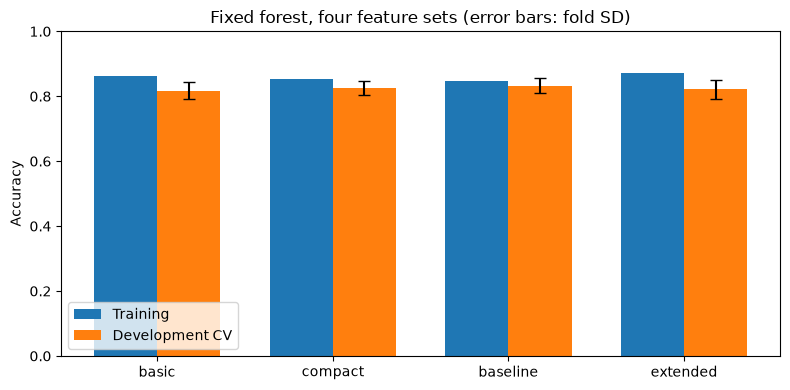

In [23]:
fig, axis = plt.subplots(figsize=(8, 4))
positions = np.arange(len(feature_table_06))
axis.bar(positions - 0.18, feature_table_06["Train accuracy"], width=0.36, label="Training")
axis.bar(positions + 0.18, feature_table_06["accuracy"], width=0.36,
         yerr=feature_table_06["Accuracy std"], capsize=4, label="Development CV")
axis.set_xticks(positions, feature_table_06.index)
axis.set_ylim(0, 1)
axis.set_ylabel("Accuracy")
axis.set_title("Fixed forest, four feature sets (error bars: fold SD)")
axis.legend()
plt.tight_layout()
plt.show()

### Explain the overall winning forest on validation folds
For each overall-winning model fitted on four folds, we score the fifth fold, shuffle one raw information group, recompute derived features, and score again. **Importance = original accuracy minus shuffled accuracy**. Ten seeded permutations per group per fold give 50 measurements per group. Positive values mean shuffling hurt prediction; near-zero or negative values do not establish that a feature is useless.

We shuffle Sex and Name together to retain their relationship with Title, and SibSp/Parch together so FamilySize and IsAlone are recomputed consistently. Age, Pclass, Fare, Embarked, and (only for extended) Cabin form separate groups. Cabin shuffling changes Deck and HasCabin together. Within-group relationships are preserved, but correlations across groups can still be broken. FarePerPerson depends on both fare and family counts, so those groups have overlapping effects.

This measures the fitted model's reliance on information, not causation, fairness, or a passenger's individual explanation. Selection reused these validation folds; importance is exploratory and is not an independent performance estimate. We do not use it to choose another subset. The displayed standard deviation describes permutations and folds, not a confidence interval. See [scikit-learn's permutation-importance guidance](https://scikit-learn.org/stable/modules/permutation_importance.html).

These importance results explain the retained overall winner (baseline), not the compact ablation candidate submitted to Kaggle.

,Mean,SD,Count
Group,,,
Sex and name/title,0.2559,0.0433,50
Family counts,0.0368,0.0187,50
Passenger class,0.0101,0.0128,50
Age,0.0077,0.0078,50
Embarkation,0.0023,0.0048,50
Fare,0.0004,0.0055,50


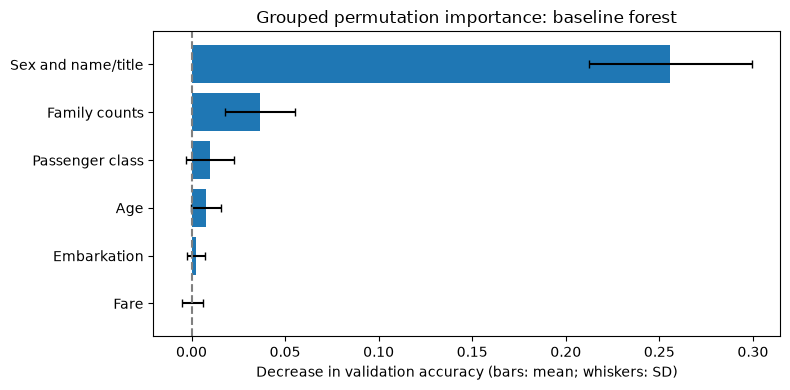

In [24]:
groups_06 = {
    "Sex and name/title": ["Sex", "Name"],
    "Passenger class": ["Pclass"], "Age": ["Age"],
    "Fare": ["Fare"], "Family counts": ["SibSp", "Parch"], "Embarkation": ["Embarked"],
}
if selected_features_06 == "extended":
    groups_06["Cabin information"] = ["Cabin"]
importance_rows_06 = []
for fold, ((_, validation_idx), fitted) in enumerate(zip(
    fold_indices_06, feature_runs_06[selected_features_06]["estimator"]
)):
    validation = X_dev.iloc[validation_idx]
    target = y_dev.iloc[validation_idx]
    reference = accuracy_score(target, fitted.predict(validation))
    np.testing.assert_allclose(reference, feature_runs_06[selected_features_06]["test_accuracy"][fold])
    rng = np.random.default_rng(SEED + fold)
    orders = [rng.permutation(len(validation)) for _ in range(10)]
    for group, columns in groups_06.items():
        for repeat, order in enumerate(orders):
            shuffled = permute_columns_together(validation, columns, order)
            drop = reference - accuracy_score(target, fitted.predict(shuffled))
            importance_rows_06.append({"Group": group, "Fold": fold + 1, "Repeat": repeat + 1, "Accuracy drop": float(drop)})
importance_detail_06 = pd.DataFrame(importance_rows_06)
importance_summary_06 = importance_detail_06.groupby("Group")["Accuracy drop"].agg(
    Mean="mean", SD=lambda values: np.std(values, ddof=0), Count="count"
).sort_values("Mean", ascending=False)
assert importance_summary_06["Count"].eq(50).all()
display(importance_summary_06.round(4))
ordered = importance_summary_06.sort_values("Mean")
fig, axis = plt.subplots(figsize=(8, 4))
axis.barh(ordered.index, ordered["Mean"], xerr=ordered["SD"], capsize=3)
axis.axvline(0, color="gray", linestyle="--")
axis.set_xlabel("Decrease in validation accuracy (bars: mean; whiskers: SD)")
axis.set_title(f"Grouped permutation importance: {selected_features_06} forest")
plt.tight_layout()
plt.show()

### Reused holdout diagnostic for the upload candidate
Fit the distinct ablation candidate on all 712 development rows and inspect the same 179-row holdout. This is a diagnostic only: no subset or threshold is selected here. Survived=1 remains positive; probabilities supply ROC-AUC and average precision.

accuracy             0.8212
precision            0.8033
recall               0.7101
f1                   0.7538
roc_auc              0.8611
average_precision    0.8357
Name: Reused holdout, dtype: float64

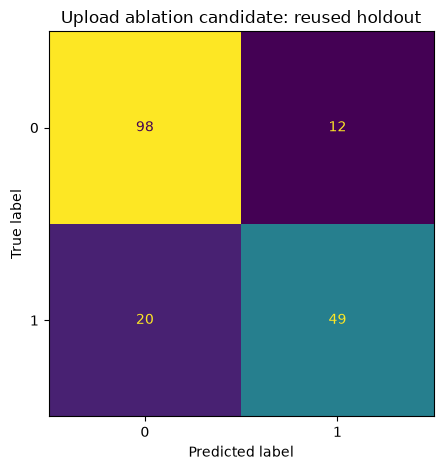

Confusion matrix: actual rows, predicted columns; classes [0, 1].


In [25]:
diagnostic_model_06 = clone(submission_pipeline_06).fit(X_dev, y_dev)
np.testing.assert_array_equal(diagnostic_model_06.classes_, [0, 1])
holdout_prediction_06 = diagnostic_model_06.predict(X_holdout)
holdout_probability_06 = diagnostic_model_06.predict_proba(X_holdout)[:, 1]
holdout_matrix_06 = confusion_matrix(y_holdout, holdout_prediction_06, labels=[0, 1])
assert holdout_matrix_06.sum() == 179
holdout_metrics_06 = {
    "accuracy": accuracy_score(y_holdout, holdout_prediction_06),
    "precision": precision_score(y_holdout, holdout_prediction_06, zero_division=0),
    "recall": recall_score(y_holdout, holdout_prediction_06, zero_division=0),
    "f1": f1_score(y_holdout, holdout_prediction_06, zero_division=0),
    "roc_auc": roc_auc_score(y_holdout, holdout_probability_06),
    "average_precision": average_precision_score(y_holdout, holdout_probability_06),
}
display(pd.Series(holdout_metrics_06, name="Reused holdout").round(4))
ConfusionMatrixDisplay.from_predictions(y_holdout, holdout_prediction_06, labels=[0, 1], colorbar=False)
plt.title("Upload ablation candidate: reused holdout")
plt.tight_layout()
plt.show()
print("Confusion matrix: actual rows, predicted columns; classes [0, 1].")

### What we learned and why this upload differs from our best model
The baseline wins at **0.8329 mean CV accuracy**. Compact scores **0.8244**, extended **0.8217**, and basic **0.8174**. The baseline exceeds basic by 1.55 percentage points, suggesting the engineered title/family bundle helps in this experiment. Removing separate sibling/spouse and parent/child counts reduces accuracy by 0.85 points, even though compact retains their sum through FamilySize and IsAlone. Adding the cabin/fare bundle reduces accuracy by 1.12 points while increasing training accuracy from 0.8473 to 0.8704, consistent with extra fit that does not transfer to these validation folds. These small, selected comparisons do not establish statistical significance or isolate individual features.

We **retain the baseline as the overall winner**. It reproduces submission 4 exactly, so after seeing the results we chose the highest-scoring non-baseline set, **compact**, for a distinct sixth ablation upload. This is an explicit delivery adjustment, not a claim that compact won the comparison. We added no configurations and used no holdout or Kaggle score to choose it. The purpose is to report what happened when we removed information, including the negative result.

For the retained baseline, grouped permutation importance shows the strongest reliance on Sex/Name/Title: average accuracy drops by **25.59 percentage points** when that group is shuffled. Family counts and their derived fields follow at **3.68 points**. Passenger class drops 1.01, age 0.77, embarkation 0.23, and fare 0.04 points. Correlated groups can substitute for one another, so low importance does not prove a feature can be removed without loss. These describe model reliance, not causal effects, and are not individual passenger explanations.

The compact candidate's reused holdout accuracy is **0.8212**, precision 0.8033, recall 0.7101, F1 0.7538, ROC-AUC 0.8611, and average precision 0.8357. Its counts are TN=98, FP=12, FN=20, TP=49. This diagnostic does not overturn development selection. Its final CSV changes **2 of 418 labels** relative to submission 4 and predicts 162 survivors. The completed Kaggle upload scored **0.77990**, our highest recorded score: 0.479 percentage points above submission 4 and 0.239 above the historical forest. Compact still scored lower in development CV. This small observed leaderboard gain does not establish general superiority or change the validation result.

### Refit and reproduce submission 6
After selection, fit the strongest non-baseline feature set on all 891 labeled passengers. Validate the CSV schema, all 418 passenger IDs in test order, binary predictions, and a round trip. The overall winner remains our retained model; this upload tests a distinct ablation. Metadata records the entire comparison, feature definitions, fold scores, grouped importance, diagnostic metrics, data hashes, and prediction hash.

The recorded Kaggle score is 0.77990. A regenerated CSV receives that score only if its hash matches the uploaded file. Changed predictions require their own upload and score.

In [26]:
final_model_06 = clone(submission_pipeline_06).fit(X, y)
submission_06 = make_submission(test["PassengerId"], final_model_06.predict(test))
submission_06_path = Path("submission_06_feature_comparison.csv")
submission_06.to_csv(submission_06_path, index=False)
reloaded_06 = pd.read_csv(submission_06_path)
pd.testing.assert_frame_equal(reloaded_06, submission_06)
assert reloaded_06.shape == (418, 2)
assert reloaded_06["PassengerId"].equals(test["PassengerId"])
assert reloaded_06["Survived"].isin([0, 1]).all() and not reloaded_06.isna().any().any()
control_06 = pd.read_csv("submission_04_random_forest_tuned.csv")
assert control_06["PassengerId"].equals(test["PassengerId"])
changes_06 = int((reloaded_06["Survived"] != control_06["Survived"]).sum())
feature_search_records_06 = []
for name, (numeric, categorical) in FEATURE_SETS.items():
    result = feature_runs_06[name]
    feature_search_records_06.append({
        "feature_set": name, "numeric": list(numeric), "categorical": list(categorical),
        "input_columns": len(numeric) + len(categorical),
        "cv_mean": {metric: float(result[f"test_{metric}"].mean()) for metric in scoring_05},
        "cv_std": {metric: float(result[f"test_{metric}"].std()) for metric in scoring_05},
        "cv_fold_accuracy": result["test_accuracy"].tolist(),
        "mean_train_accuracy": float(result["train_accuracy"].mean()),
        "mean_fit_seconds": float(result["fit_time"].mean()),
        "encoded_columns_per_fold": [len(model.named_steps["preprocess"].get_feature_names_out()) for model in result["estimator"]],
    })
recorded_submission_06_sha256 = "5a9d368108b4deb45559e59ead25c4d88d2bd681764516efd9e29958459cbcbb"
submission_06_sha256 = hashlib.sha256(submission_06_path.read_bytes()).hexdigest()
matches_recorded_submission_06 = submission_06_sha256 == recorded_submission_06_sha256
experiment_06 = {
    "experiment": "06_feature_comparison", "status": "matches_recorded_submission" if matches_recorded_submission_06 else "prepared_not_uploaded",
    "kaggle_score": 0.77990 if matches_recorded_submission_06 else None,
    "overall_winner_feature_set": selected_features_06,
    "submission_feature_set": submission_features_06, "selection_metric": "accuracy",
    "submission_decision": "After baseline won, prepare strongest non-baseline set as a distinct ablation; retain overall winner. No search expansion.",
    "importance_feature_set": selected_features_06,
    "selection_ties": "fewer input columns, then basic/compact/baseline/extended order",
    "seed": SEED, "development_rows": len(X_dev), "holdout_rows": len(X_holdout), "cv_folds": cv.n_splits,
    "search_results": feature_search_records_06,
    "parameters": final_model_06.named_steps["model"].get_params(),
    "holdout_metrics": holdout_metrics_06, "holdout_confusion_matrix": holdout_matrix_06.tolist(),
    "holdout_previously_examined": True,
    "importance_groups": groups_06, "importance_repeats_per_fold": 10,
    "importance_summary": importance_summary_06.to_dict(orient="index"),
    "importance_measurements": importance_rows_06,
    "python": platform.python_version(), "sklearn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__,
    "training_data_sha256": hashlib.sha256(train.to_csv(index=False).encode()).hexdigest(),
    "test_data_sha256": hashlib.sha256(test.to_csv(index=False).encode()).hexdigest(),
    "submission_file": submission_06_path.name,
    "submission_sha256": submission_06_sha256,
    "submission_rows": len(reloaded_06), "predicted_survivors": int(reloaded_06["Survived"].sum()),
    "predictions_changed_from_submission_04": changes_06,
    "recorded_submission": {
        "date": "2026-11-14", "score": 0.77990,
        "submission_sha256": recorded_submission_06_sha256,
        "evidence": "assets/submission_06_score.png",
    },
}
Path("outputs/experiment_06.json").write_text(json.dumps(experiment_06, indent=2) + "\n")
print(f"Generated {submission_06_path}: {len(reloaded_06)} checked rows, feature set {submission_features_06}")
print(f"Predicted survivors: {reloaded_06['Survived'].sum()}; labels changed from submission 4: {changes_06}")
print(f"SHA-256: {experiment_06['submission_sha256']}")
if matches_recorded_submission_06:
    print("Matches the November 14 submission: recorded Kaggle score 0.77990. Six uploads confirmed.")
else:
    print("Predictions differ from the recorded upload; this file has no Kaggle score yet.")
display(reloaded_06.head())

Generated submission_06_feature_comparison.csv: 418 checked rows, feature set compact
Predicted survivors: 162; labels changed from submission 4: 2
SHA-256: 5a9d368108b4deb45559e59ead25c4d88d2bd681764516efd9e29958459cbcbb
Matches the November 14 submission: recorded Kaggle score 0.77990. Six uploads confirmed.


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


### Completed Kaggle submission
We submitted `submission_06_feature_comparison.csv` on **November 14, 2026**. Kaggle reported **0.77990**, the highest recorded score in our experiments. We now have **six of six required non-dummy submissions**.

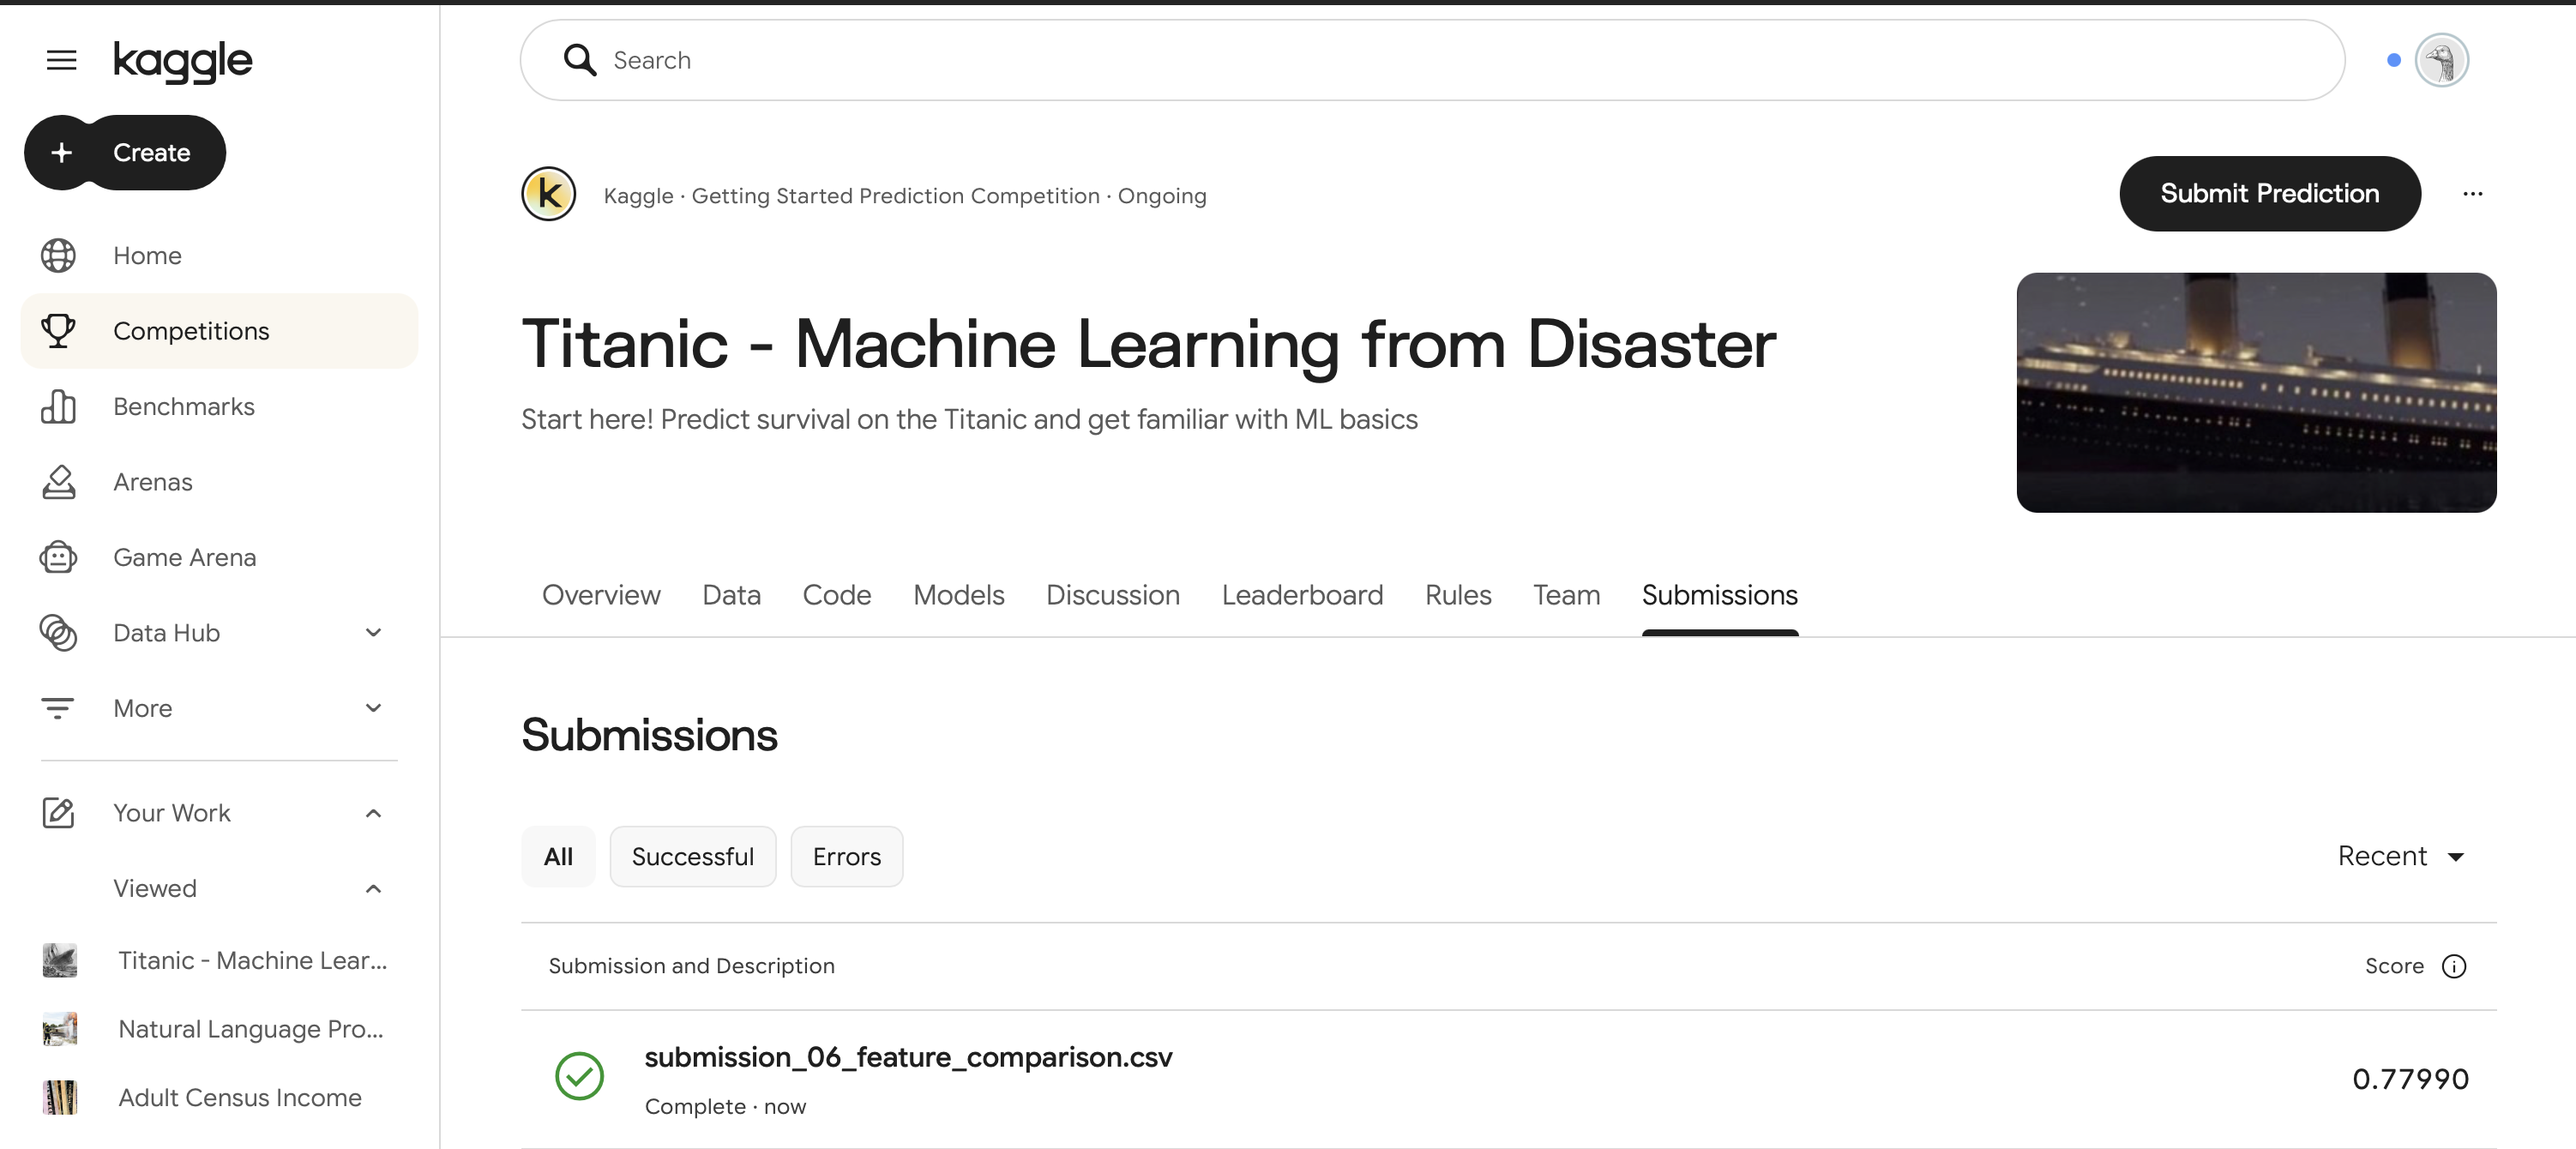

The export cell checks the regenerated CSV hash before associating it with this score. The results and overall conclusions are summarized below.

## 12. Consolidated results
All six required non-dummy submissions completed successfully. Kaggle accuracy below is the observed score of each original upload. Development CV uses five identical stratified folds on 712 rows with preprocessing fitted separately inside each training fold.

| Upload | Method / experiment | Development CV accuracy | Kaggle accuracy | Main result |
| --- | --- | --- | --- | --- |
| Dummy | Always predict 0 | 0.6166 | 0.62200 | Reference point; detects no survivors |
| 1 | Original logistic regression | Not comparable | 0.76794 | First linear-model submission |
| 2 | Original random forest | Not comparable | 0.77751 | First tree-ensemble submission |
| 3 | Gradient boosting | 0.8287 | 0.76315 | Did not beat the cleaned forest in validation |
| 4 | Forest depth/leaf search | **0.8329** | 0.77511 | Original cleaned settings won; deeper trees overfit |
| 5 | Logistic C/class-weight search | 0.8231 | 0.77033 | Small accuracy change; class weighting traded precision for recall |
| 6 | Compact-feature forest | 0.8244 | **0.77990** | Best recorded Kaggle score; removing separate family counts lowered CV accuracy |

The original logistic and forest local estimates used preprocessing before the split, so they are not presented as comparable CV results. Their cleaned counterparts are evaluated in sections 5 and 10. Submission 4 repeats the cleaned forest control's settings and predictions; it documents the negative tuning result and the cleaned pipeline's scored upload. Submission 6 was intentionally an ablation candidate, while the original feature set remained the development-CV winner.

**Best development result:** the cleaned baseline forest, mean accuracy 0.8329 (fold SD 0.0231). **Best observed Kaggle result:** the compact forest, 0.77990. These answer different evaluation questions. The compact export differs from submission 4 in only two of 418 labels; its leaderboard advantage is 0.479 percentage points. A small leaderboard gain does not establish general superiority or retroactively change the validation outcome.

## 13. Conclusion
Passenger attributes provide useful predictive information about Titanic survival. Our strongest observed Kaggle result was **77.990% accuracy**, compared with **62.200%** for the majority-class dummy, an improvement of **15.790 percentage points**. We tried three non-dummy model families: logistic regression, random forest, and gradient boosting, with six scored non-dummy uploads across the original models and controlled experiments.

The experiments support three practical conclusions. First, correct validation matters: fitting preprocessing inside each fold prevents leakage, while keeping the folds fixed makes comparisons more interpretable. Second, more model complexity or more features did not automatically improve validation accuracy. Deeper forests fit training data better but generalized worse on these folds; the cabin/fare feature bundle also failed to improve the baseline. Third, accuracy alone hides error tradeoffs. The dummy missed every survivor, balanced logistic training increased recall at the expense of precision and accuracy, and ranking metrics did not always order models the same way as accuracy.

Our feature comparison retained the original forest feature set as the CV winner. Grouped permutation analysis showed the strongest reliance on sex/name-title information, followed by family information. Removing separate family counts lowered CV accuracy, although the compact model produced our best Kaggle score. We report both findings rather than treat the leaderboard as a substitute for validation.

For continued model development, the cleaned baseline forest is the reference configuration supported by our selection protocol. The compact forest is the best submitted prediction file observed so far. Further work should improve the independence and realism of validation before expanding the search. The final deliverable records the successful uploads, reproducible preprocessing and training, measured tradeoffs, and limitations.

## 14. Limitations and future work
The dataset is small, and model rankings vary across validation folds and Kaggle's scored data. Hyperparameter and feature searches reused the development folds, introducing selection bias. The 179-row holdout had already been examined during checkpoint 2, so it is a diagnostic rather than an untouched final test. Fold standard deviations are not confidence intervals, and we have not established statistically significant differences among the strongest models.

Relatives and shared-ticket passengers can appear in both training and validation folds. A useful next experiment would compare the current stratified validation with group-aware splits based on family/ticket groups. That analysis would ask whether the models generalize to unseen travel groups; it has not been performed here. Nested validation could also separate model selection from performance estimation.

Further feature experiments could isolate cabin information and fare normalization separately, instead of adding them as a bundle, and test whether age imputation conditioned on training-only passenger groups improves results. Any learned feature construction must stay inside the fold. These are proposed future experiments, not completed work.

Permutation importance describes reliance of the fitted model on information groups, not causal effects or individual explanations. Correlated groups can substitute for one another, and shuffling can create unrealistic combinations across groups. This retrospective historical classifier has not been evaluated for fairness or real-world deployment.

The original checkpoint workflows imputed before splitting; their local scores are excluded from the final comparable-validation table. The original Kaggle scores remain valid records of those uploaded files. Original upload CSVs for checkpoints 1–2 were not all retained, so exact prediction-by-prediction reconstruction of those historical models is not claimed. Later upload scores are associated with regenerated files only when the recorded CSV hashes match.